# Exp1034 DNA A260: volume and concentration sensitivity

Run: `dna-a260-f5-20261007T182308Z-4a000d5d`, 7 October 2026.

**Concentration correction:** the user reported A30 = **70 ng/µL**, superseding 16 ng/µL in the original acquisition metadata. With the same twofold dilutions, A30–A25 are **70, 35, 17.5, 8.75, 4.375, 2.1875 ng/µL**. The raw files and original fields remain unchanged. Downstream concentrations are nominal and have not been independently measured by this read.

This notebook performs file-based analysis only; it imports no reader or robot driver. Run all cells from this directory. All original observations are retained, with volume-matched blank subtraction. See the accompanying PDF or HTML for the integrated interpretation.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
from analysis import analyze
from plot_analysis import make_figures
from verify_analysis import verify

root = Path.cwd()
assert (root / "inputs/raw_a260.csv").is_file(), "Run from the analysis folder."
summary = analyze(root, n_boot=10_000, seed=1034)
print(summary["concentration_note"])
print(f"{summary['wells']} wells; {summary['samples']} DNA samples; {summary['blanks']} blanks")

User corrected A30 to 70 ng/uL. Original concentration metadata is preserved and superseded for analysis; other tubes assume the same twofold dilution. No independent concentration verification.
96 wells; 72 DNA samples; 24 blanks


## Identity and correction audit

The original raw IDs, source tubes, planned volumes, replicates and old concentration labels must match the run manifest and saved layout. The analysis then adds the user-corrected concentration without changing the original exported concentration column.

Subtract the mean of six blanks at the same volume from each reading. SD is the sample SD (n−1). Electronic label agreement does not independently verify the contents of a physical well.

In [2]:
audit = pd.read_csv(root / "tables/sample_id_audit.csv")
assert audit.all_labels_match.all()
display(audit[["well", "all_labels_match", "exported_concentration_ng_uL", "analysis_concentration_ng_uL"]].head(12))
display(pd.read_csv(root / "tables/blank_statistics.csv"))

,well,all_labels_match,exported_concentration_ng_uL,analysis_concentration_ng_uL
0,A1,True,2.0,8.7500
1,A10,True,0.0,0.0000
2,A11,True,0.5,2.1875
3,A12,True,0.0,0.0000
4,A2,True,4.0,17.5000
5,A3,True,2.0,8.7500
6,A4,True,16.0,70.0000
7,A5,True,4.0,17.5000
8,A6,True,2.0,8.7500
9,A7,True,0.0,0.0000


,volume_uL,n,blank_mean,blank_sd,mean_ci95_low,mean_ci95_high,sd_boot_ci95_low,sd_boot_ci95_high,raw_threshold_3_3sd,raw_threshold_10sd,blank_wells
0,50,6,0.057542,0.000330,0.057303,0.057785,0.000153,0.000394,0.058631,0.060843,A12;C6;E4;F7;G2;H5
1,75,6,0.057558,0.001054,0.056841,0.058347,0.000461,0.001296,0.061036,0.068098,A7;B2;D12;E11;F10;H4
2,100,6,0.057802,0.001046,0.057065,0.058585,0.000404,0.001357,0.061253,0.068261,A10;B5;C12;D3;E6;H7
3,200,6,0.059362,0.002242,0.057813,0.060952,0.000599,0.002674,0.066762,0.081786,A9;B12;C7;D10;E1;H6


## Practical comparison at the lowest tested concentration

100 µL is the best supported starting choice for low-level work on this plate. At 2.1875 ng/µL, CV is 8.5% at 100 µL and 8.0% at 200 µL, versus 18.9% at 75 µL. The 50 µL triplicate has CV 100.5%, driven by elevated D9. D9 remains in every primary result. No sample below 2.1875 ng/µL was tested.

In [3]:
groups = pd.read_csv(root / "tables/group_summary.csv")
display(groups[groups.concentration_ng_uL == 2.1875][["volume_uL", "concentration_ng_uL", "mean_corrected", "sample_sd", "cv_percent", "wells"]])
display(pd.read_csv(root / "tables/volume_decisions.csv"))

,volume_uL,concentration_ng_uL,mean_corrected,sample_sd,cv_percent,wells
0,50,2.1875,0.010455,0.010508,100.509196,A8;C10;D9
6,75,2.1875,0.006568,0.001239,18.867609,A11;C1;D8
12,100,2.1875,0.008618,0.000732,8.491746,E2;F9;H11
18,200,2.1875,0.017158,0.001368,7.974881,E5;F8;G11


,volume_uL,lowest_tested_ng_uL,lowest_tested_mass_ng,cv_at_lowest_percent,signal_in_blank_sd_at_lowest,all_3_above_blank_screen_at_lowest,lowest_strict_screen_ng_uL,strict_screen_definition
0,50,2.1875,109.3750,100.509196,31.664861,True,8.750,All 3 wells > 10 blank SD and corrected CV <= ...
1,75,2.1875,164.0625,18.867609,6.232206,True,8.750,All 3 wells > 10 blank SD and corrected CV <= ...
2,100,2.1875,218.7500,8.491746,8.239849,True,4.375,All 3 wells > 10 blank SD and corrected CV <= ...
3,200,2.1875,437.5000,7.974881,7.651818,True,4.375,All 3 wells > 10 blank SD and corrected CV <= ...


## Fits and uncertainty

Free-intercept OLS fits use individual sample wells. The lower-range comparison is fixed to the four lowest concentrations (2.1875–17.5 ng/µL). No blanks are fitted as concentration-zero standards. RMSE is √(SSE/n).

10,000 bootstrap resamples with seed 1034 resample sample wells within each condition and blanks within each volume. Each resampled blank mean is shared across its six concentrations. Group-departure intervals excluding zero are exploratory evidence of departure from a line, unadjusted for multiple comparisons. Intervals exclude independent preparation, day-to-day and stock-concentration uncertainty.

In [4]:
display(pd.read_csv(root / "tables/linear_fits.csv"))
display(pd.read_csv(root / "tables/group_departures.csv"))

,n,slope,intercept,r_squared,residual_rmse,residual_sd_n_minus_2,fit_kind,volume_uL,concentration_ng_uL,slope_ci95_low,slope_ci95_high,intercept_ci95_low,intercept_ci95_high,fitted_concentrations
0,18,0.001488,0.004183,0.982847,0.004656,0.004938,concentration_full,50.0,NaN,0.001381,0.001589,0.001478,0.007635,2.1875;4.375;8.75;17.5;35;70
1,12,0.001293,0.005422,0.725505,0.004666,0.005111,concentration_low,50.0,NaN,0.000786,0.001624,0.001100,0.012594,2.1875;4.375;8.75;17.5
2,18,0.002421,0.002872,0.997910,0.002624,0.002784,concentration_full,75.0,NaN,0.002370,0.002461,0.001717,0.003990,2.1875;4.375;8.75;17.5;35;70
3,12,0.002412,0.002410,0.990745,0.001367,0.001497,concentration_low,75.0,NaN,0.002299,0.002521,0.001015,0.003737,2.1875;4.375;8.75;17.5
4,18,0.003385,0.002231,0.999329,0.002077,0.002203,concentration_full,100.0,NaN,0.003344,0.003424,0.001095,0.003299,2.1875;4.375;8.75;17.5;35;70
5,12,0.003413,0.001606,0.995331,0.001371,0.001502,concentration_low,100.0,NaN,0.003250,0.003589,0.000377,0.002772,2.1875;4.375;8.75;17.5
6,18,0.006598,0.007465,0.998769,0.005487,0.005820,concentration_full,200.0,NaN,0.006521,0.006691,0.005352,0.009508,2.1875;4.375;8.75;17.5;35;70
7,12,0.006931,0.003731,0.995228,0.002815,0.003083,concentration_low,200.0,NaN,0.006734,0.007098,0.001593,0.005764,2.1875;4.375;8.75;17.5
8,12,0.000059,0.004462,0.320611,0.004866,0.005331,volume,NaN,2.1875,0.000009,0.000096,-0.000813,0.012785,NaN
9,12,0.000158,0.001612,0.982234,0.001212,0.001328,volume,NaN,4.3750,0.000142,0.000174,-0.000069,0.003282,NaN


,fit_kind,volume_uL,concentration_ng_uL,departure,ci95_low,ci95_high,excludes_zero
0,concentration_full,50,2.1875,0.003017,-0.002030,0.011375,False
1,concentration_full,50,4.3750,-0.001008,-0.004160,0.001511,False
2,concentration_full,50,8.7500,-0.002227,-0.005081,-0.000127,True
3,concentration_full,50,17.5000,-0.001209,-0.003581,0.000843,False
4,concentration_full,50,35.0000,0.001756,-0.000835,0.004560,False
5,concentration_full,50,70.0000,-0.000329,-0.002055,0.001451,False
6,concentration_full,75,2.1875,-0.001599,-0.002661,-0.000511,True
7,concentration_full,75,4.3750,0.000505,-0.000919,0.001778,False
8,concentration_full,75,8.7500,-0.000099,-0.000911,0.000750,False
9,concentration_full,75,17.5000,-0.000956,-0.002274,0.000298,False


## Exploratory limits

DL = 3.3 × blank sample SD / slope; QL = 10 × blank sample SD / slope. These are noise-based estimates, not validated limits. All 3 wells above 10 blank SD plus corrected CV ≤10% is an illustrative, post hoc screen, not a predefined acceptance criterion. The screen first passes at 8.75 ng/µL for 50/75 µL and 4.375 ng/µL for 100/200 µL. This does not negate the detectable lower signals.

No path-length correction was applied; do not infer actual DNA concentration, purity or actual fill volume from these readings alone.

In [5]:
display(pd.read_csv(root / "tables/exploratory_limits.csv"))
display(pd.read_csv(root / "tables/d9_sensitivity.csv"))
figures = make_figures(root)
print(f"Exported {len(figures)} PNG/SVG figure pairs")

,volume_uL,fit_kind,metric,estimate_ng_uL,ci95_low,ci95_high,mass_ng,bootstrap_positive_slope_fraction,status
0,50,concentration_full,DL,0.732315,0.337666,0.887754,36.615763,1,Exploratory blank-noise estimate; no independe...
1,50,concentration_full,QL,2.219137,1.023229,2.690164,110.956856,1,Exploratory blank-noise estimate; no independe...
2,50,concentration_low,DL,0.842412,0.370866,1.286149,42.120580,1,Exploratory blank-noise estimate; no independe...
3,50,concentration_low,QL,2.552762,1.123836,3.897422,127.638120,1,Exploratory blank-noise estimate; no independe...
4,75,concentration_full,DL,1.436771,0.626390,1.767398,107.757824,1,Exploratory blank-noise estimate; no independe...
5,75,concentration_full,QL,4.353851,1.898153,5.355750,326.538862,1,Exploratory blank-noise estimate; no independe...
6,75,concentration_low,DL,1.442216,0.621513,1.781906,108.166183,1,Exploratory blank-noise estimate; no independe...
7,75,concentration_low,QL,4.370351,1.883372,5.399716,327.776312,1,Exploratory blank-noise estimate; no independe...
8,100,concentration_full,DL,1.019737,0.395965,1.318449,101.973724,1,Exploratory blank-noise estimate; no independe...
9,100,concentration_full,QL,3.090113,1.199893,3.995299,309.011286,1,Exploratory blank-noise estimate; no independe...


,analysis,low_group_n,low_mean,low_sd,low_cv_percent,n,slope,intercept,r_squared,residual_rmse,residual_sd_n_minus_2
0,Primary: all wells,3,0.010455,0.010508,100.509196,18,0.001488,0.004183,0.982847,0.004656,0.004938
1,Sensitivity only: omit D9,2,0.004403,0.001054,23.927080,17,0.001522,0.002459,0.993922,0.002835,0.003018


Exported 15 PNG/SVG figure pairs


### 01  Plate layout and electronic identity audit

All 96 raw sample IDs match both the run manifest and the experiment layout. There are 72 DNA wells and 24 A31 buffer blanks. Original concentration metadata uses 16 ng/µL for A30; this map uses the user-corrected 70 ng/µL stock and nominal twofold dilutions. Electronic agreement does not independently prove physical contents.

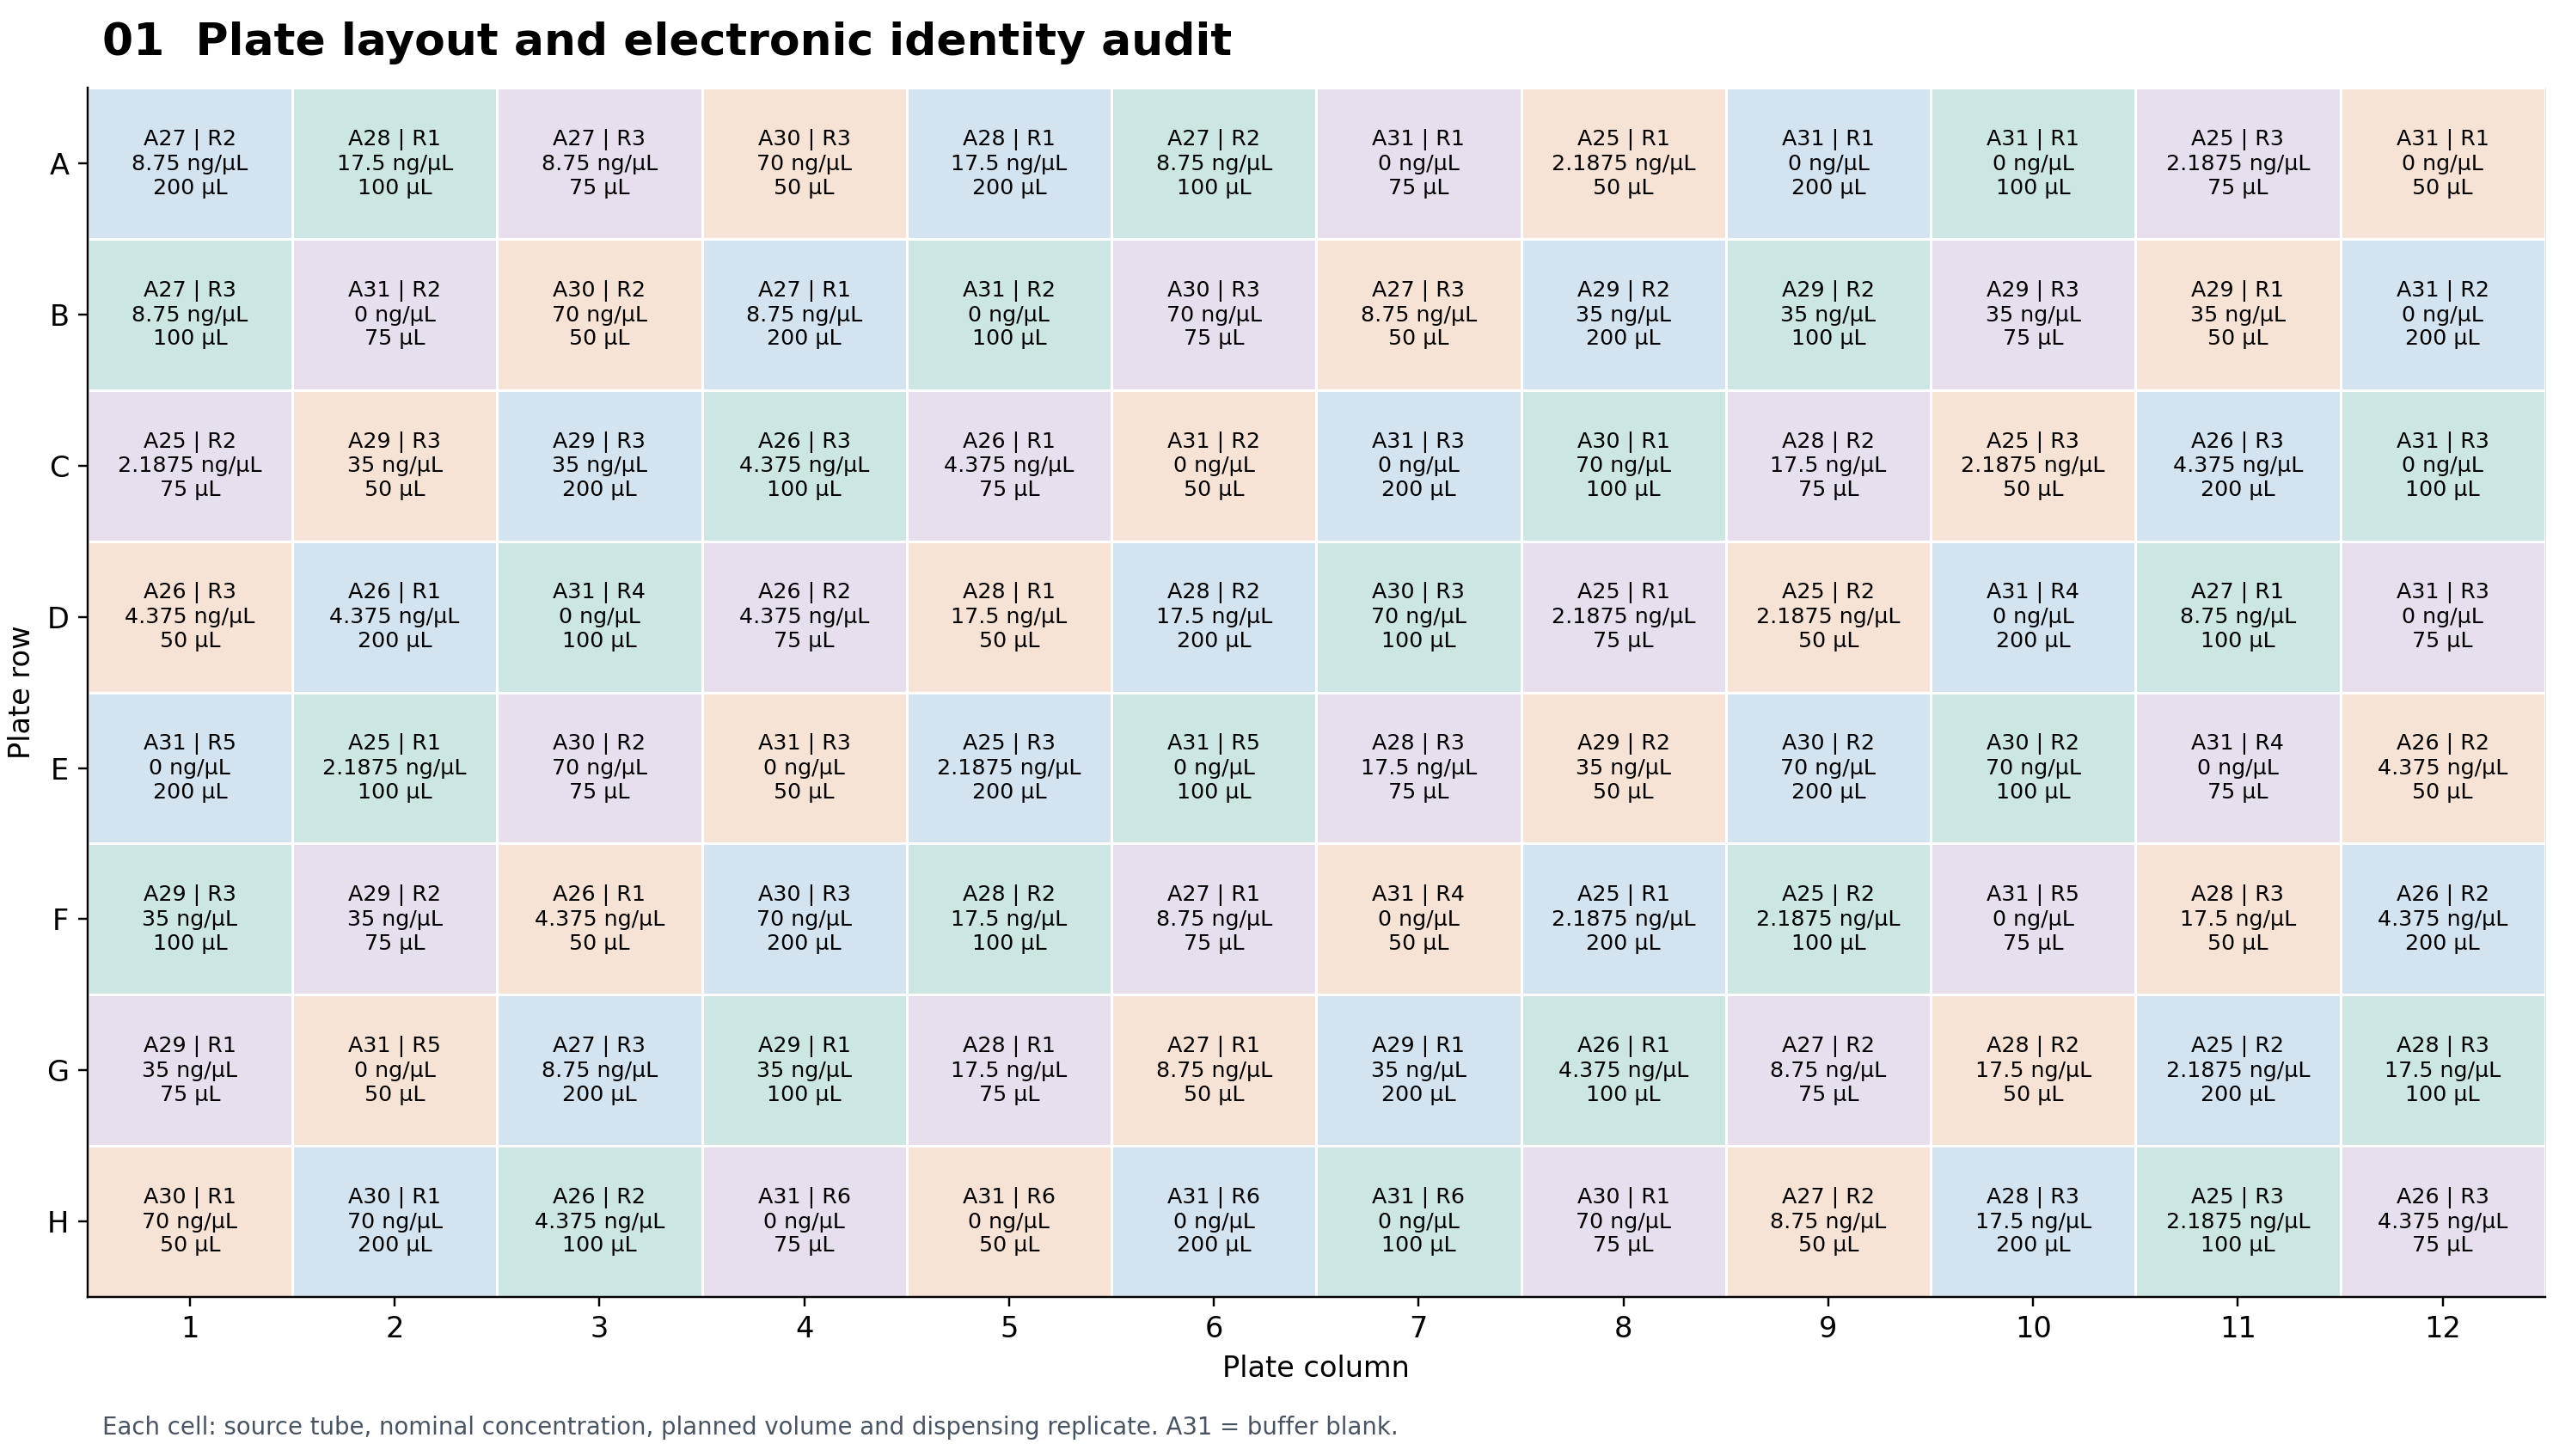

In [6]:
figure = figures[0]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 02  Raw and corrected readings retain every well

All 96 readings are finite. Raw A260 ranges from 0.05649 to 0.53148 OD. Each well is corrected with its own volume's blank mean. D9 is outlined for follow-up, not excluded. Neither heatmap measures actual fill volumes.

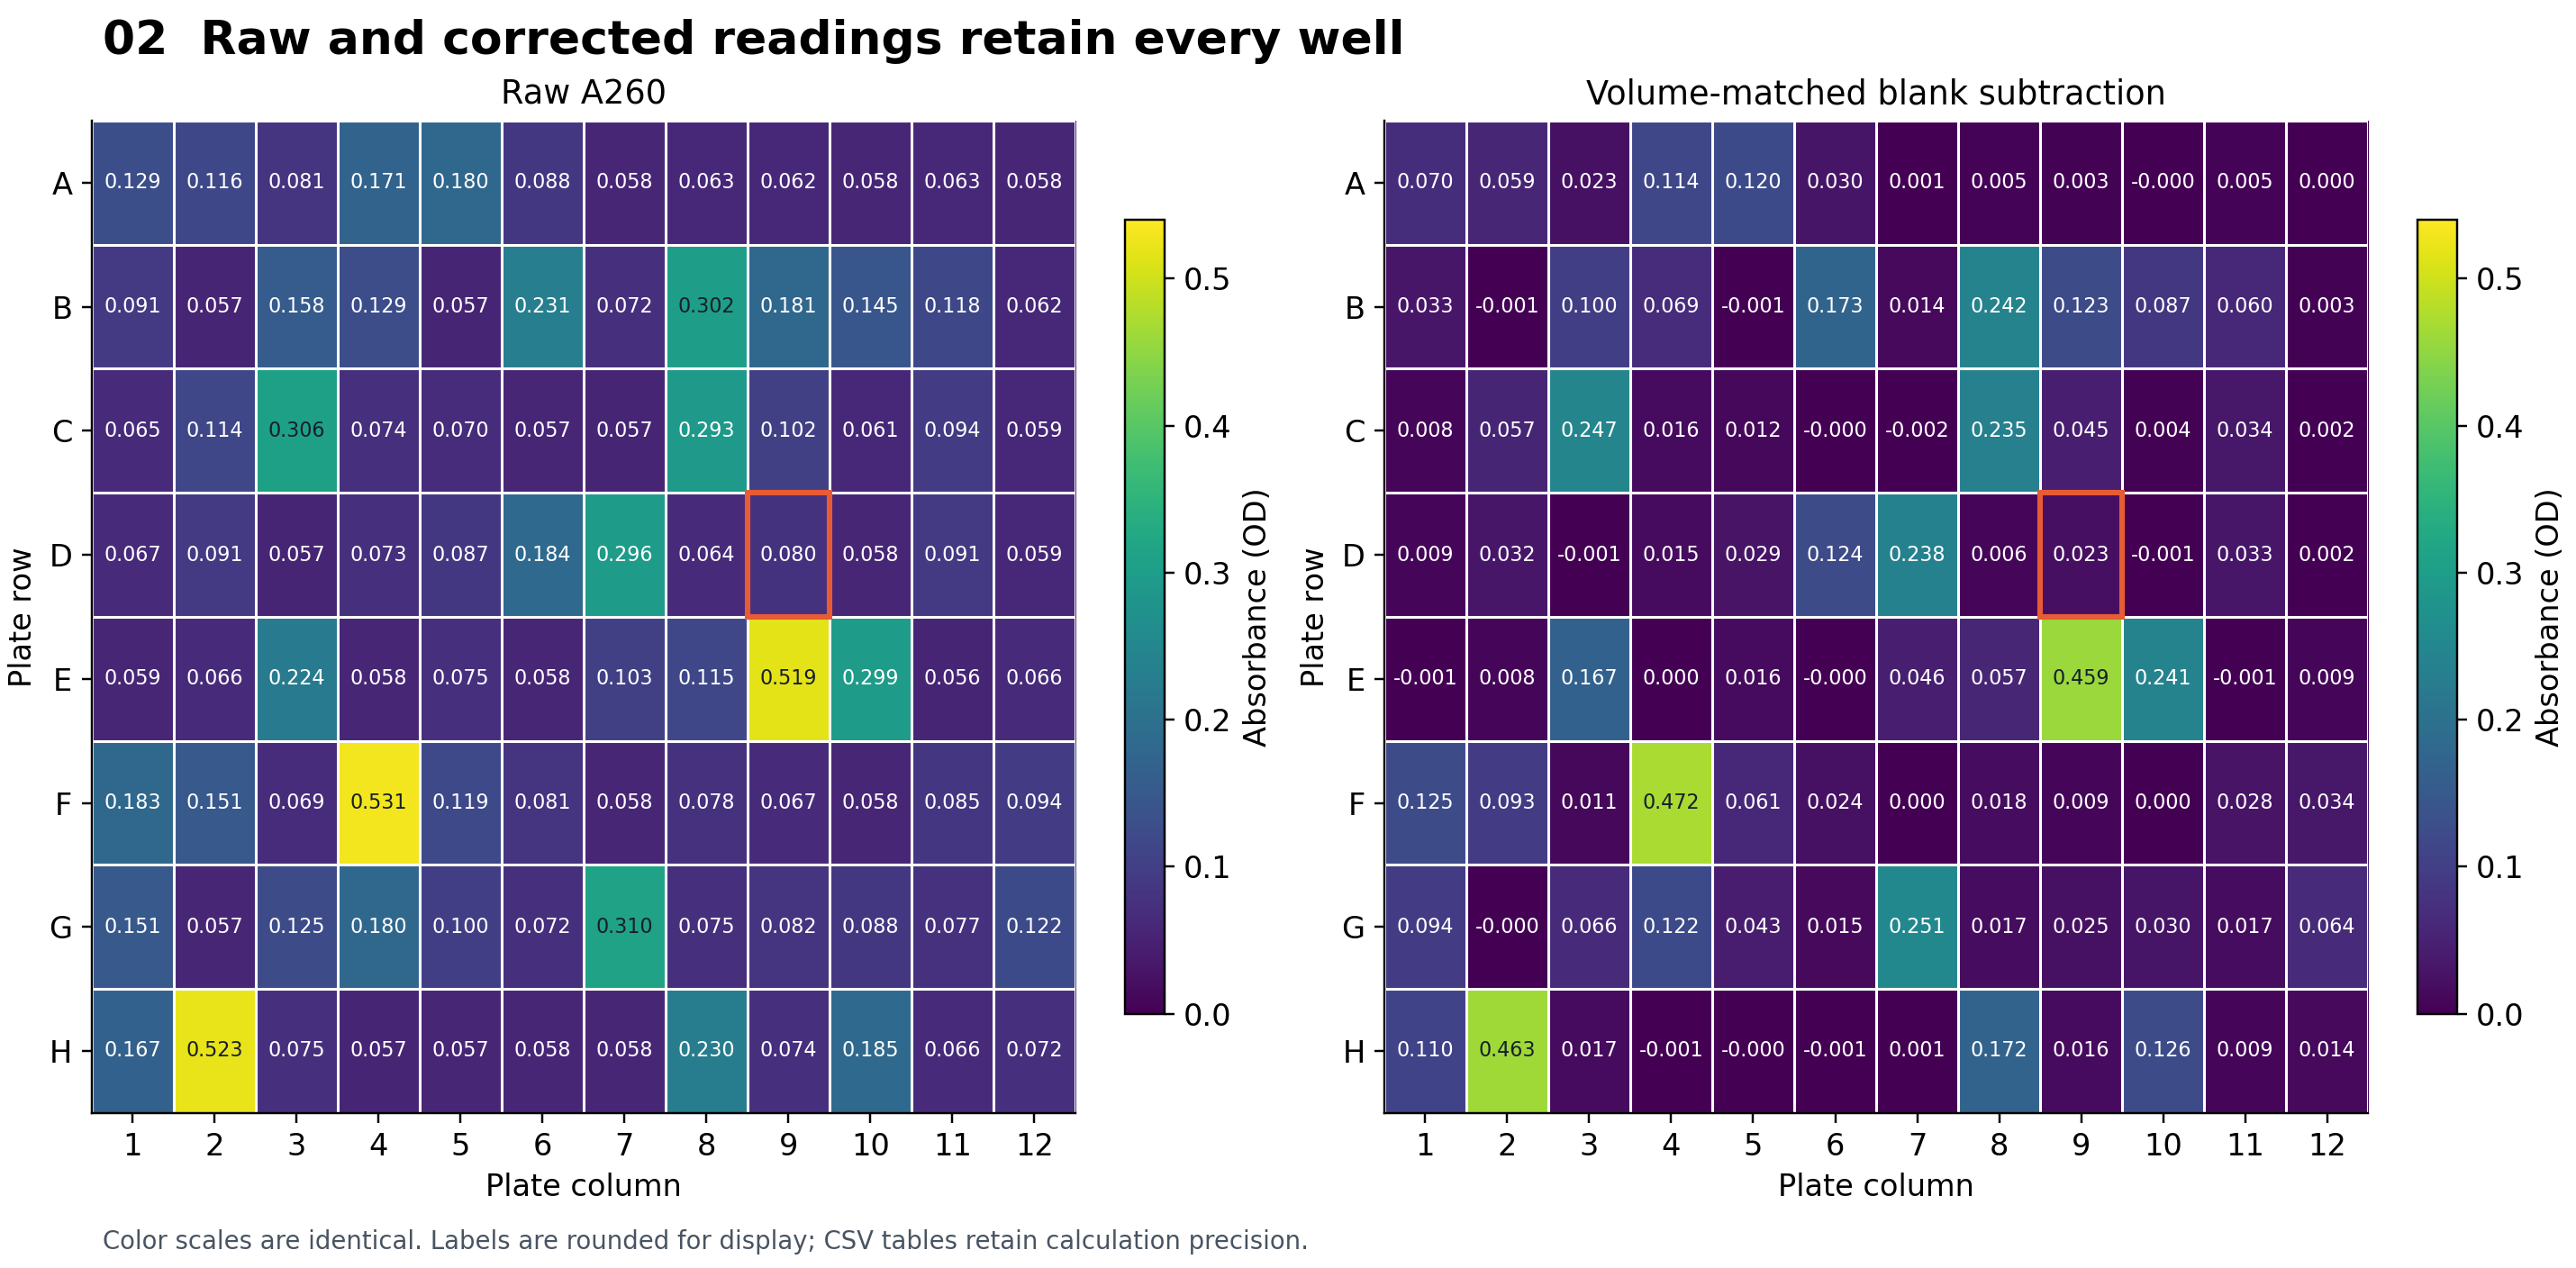

In [7]:
figure = figures[1]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 03  The 50 µL DNA-run blanks are quiet

Blank SDs are 0.000330, 0.001054, 0.001046 and 0.002242 OD at 50, 75, 100 and 200 µL. The high 50 µL background seen in the earlier Orange G run is absent here. This is a different preparation and wavelength; it does not identify the cause of the earlier problem.

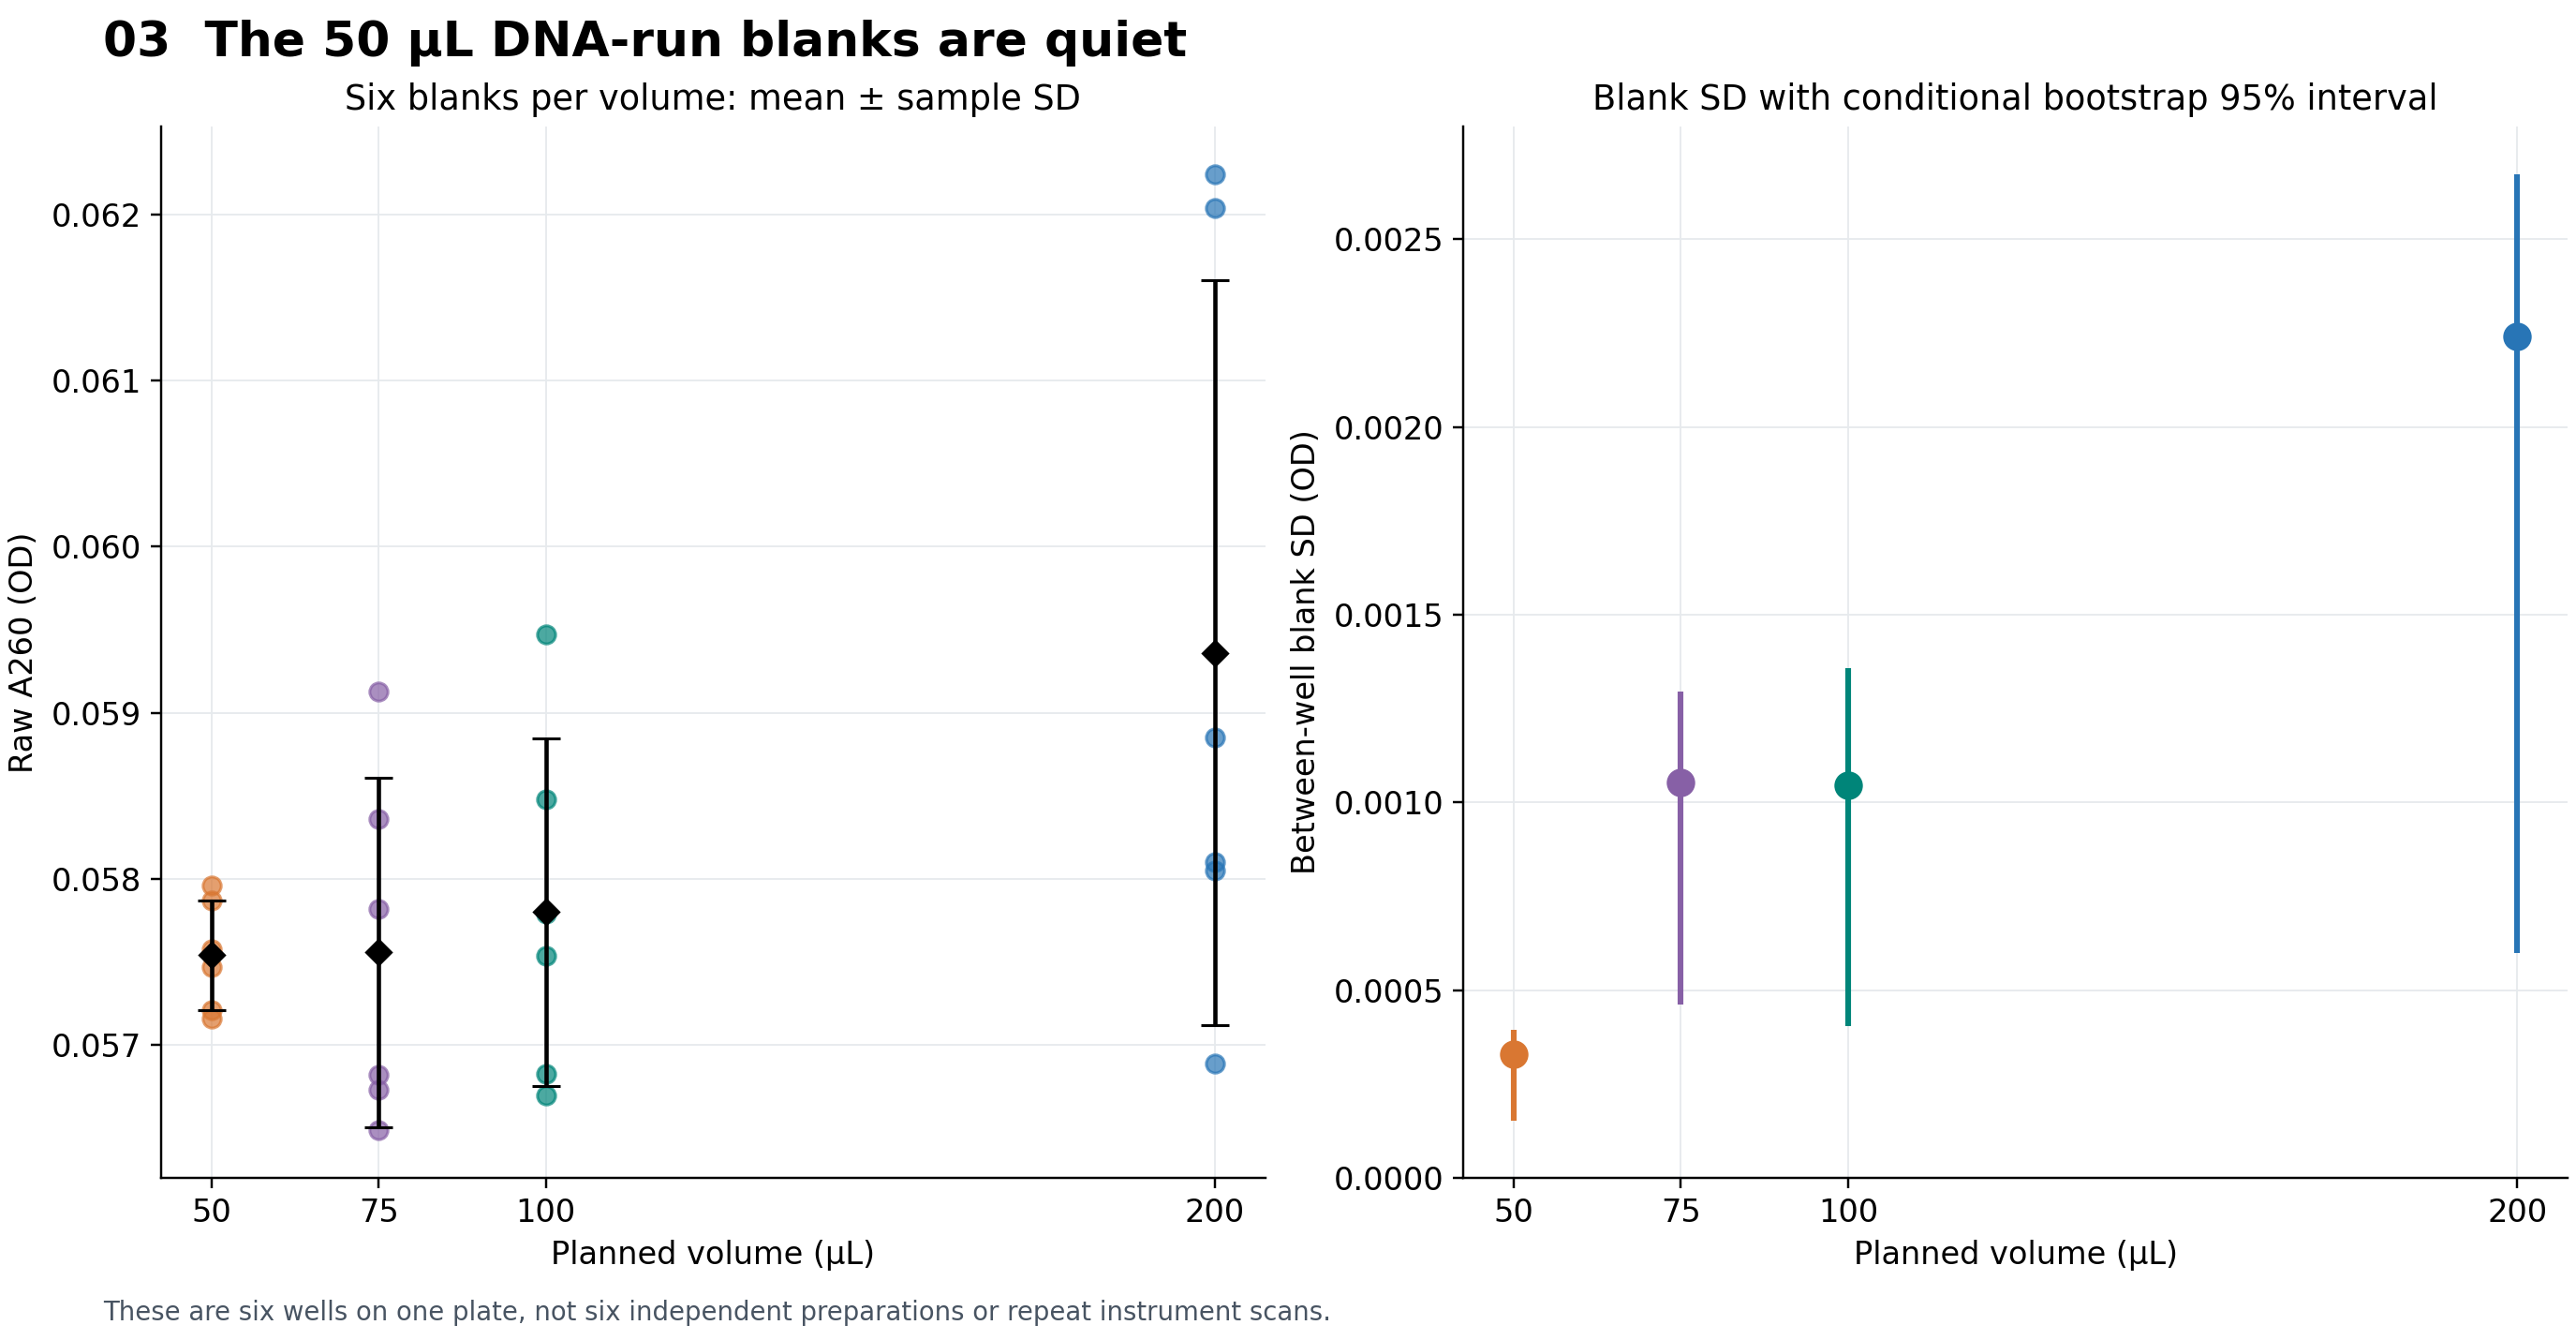

In [8]:
figure = figures[2]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 04  Concentration-response curves at each volume

Responses rise strongly with nominal concentration at every volume. Full-range R² values are high, but this alone does not establish strict linearity or low-end accuracy. Fit all 18 sample wells per panel with a free intercept; the residual analysis shows where a straight line misses group means.

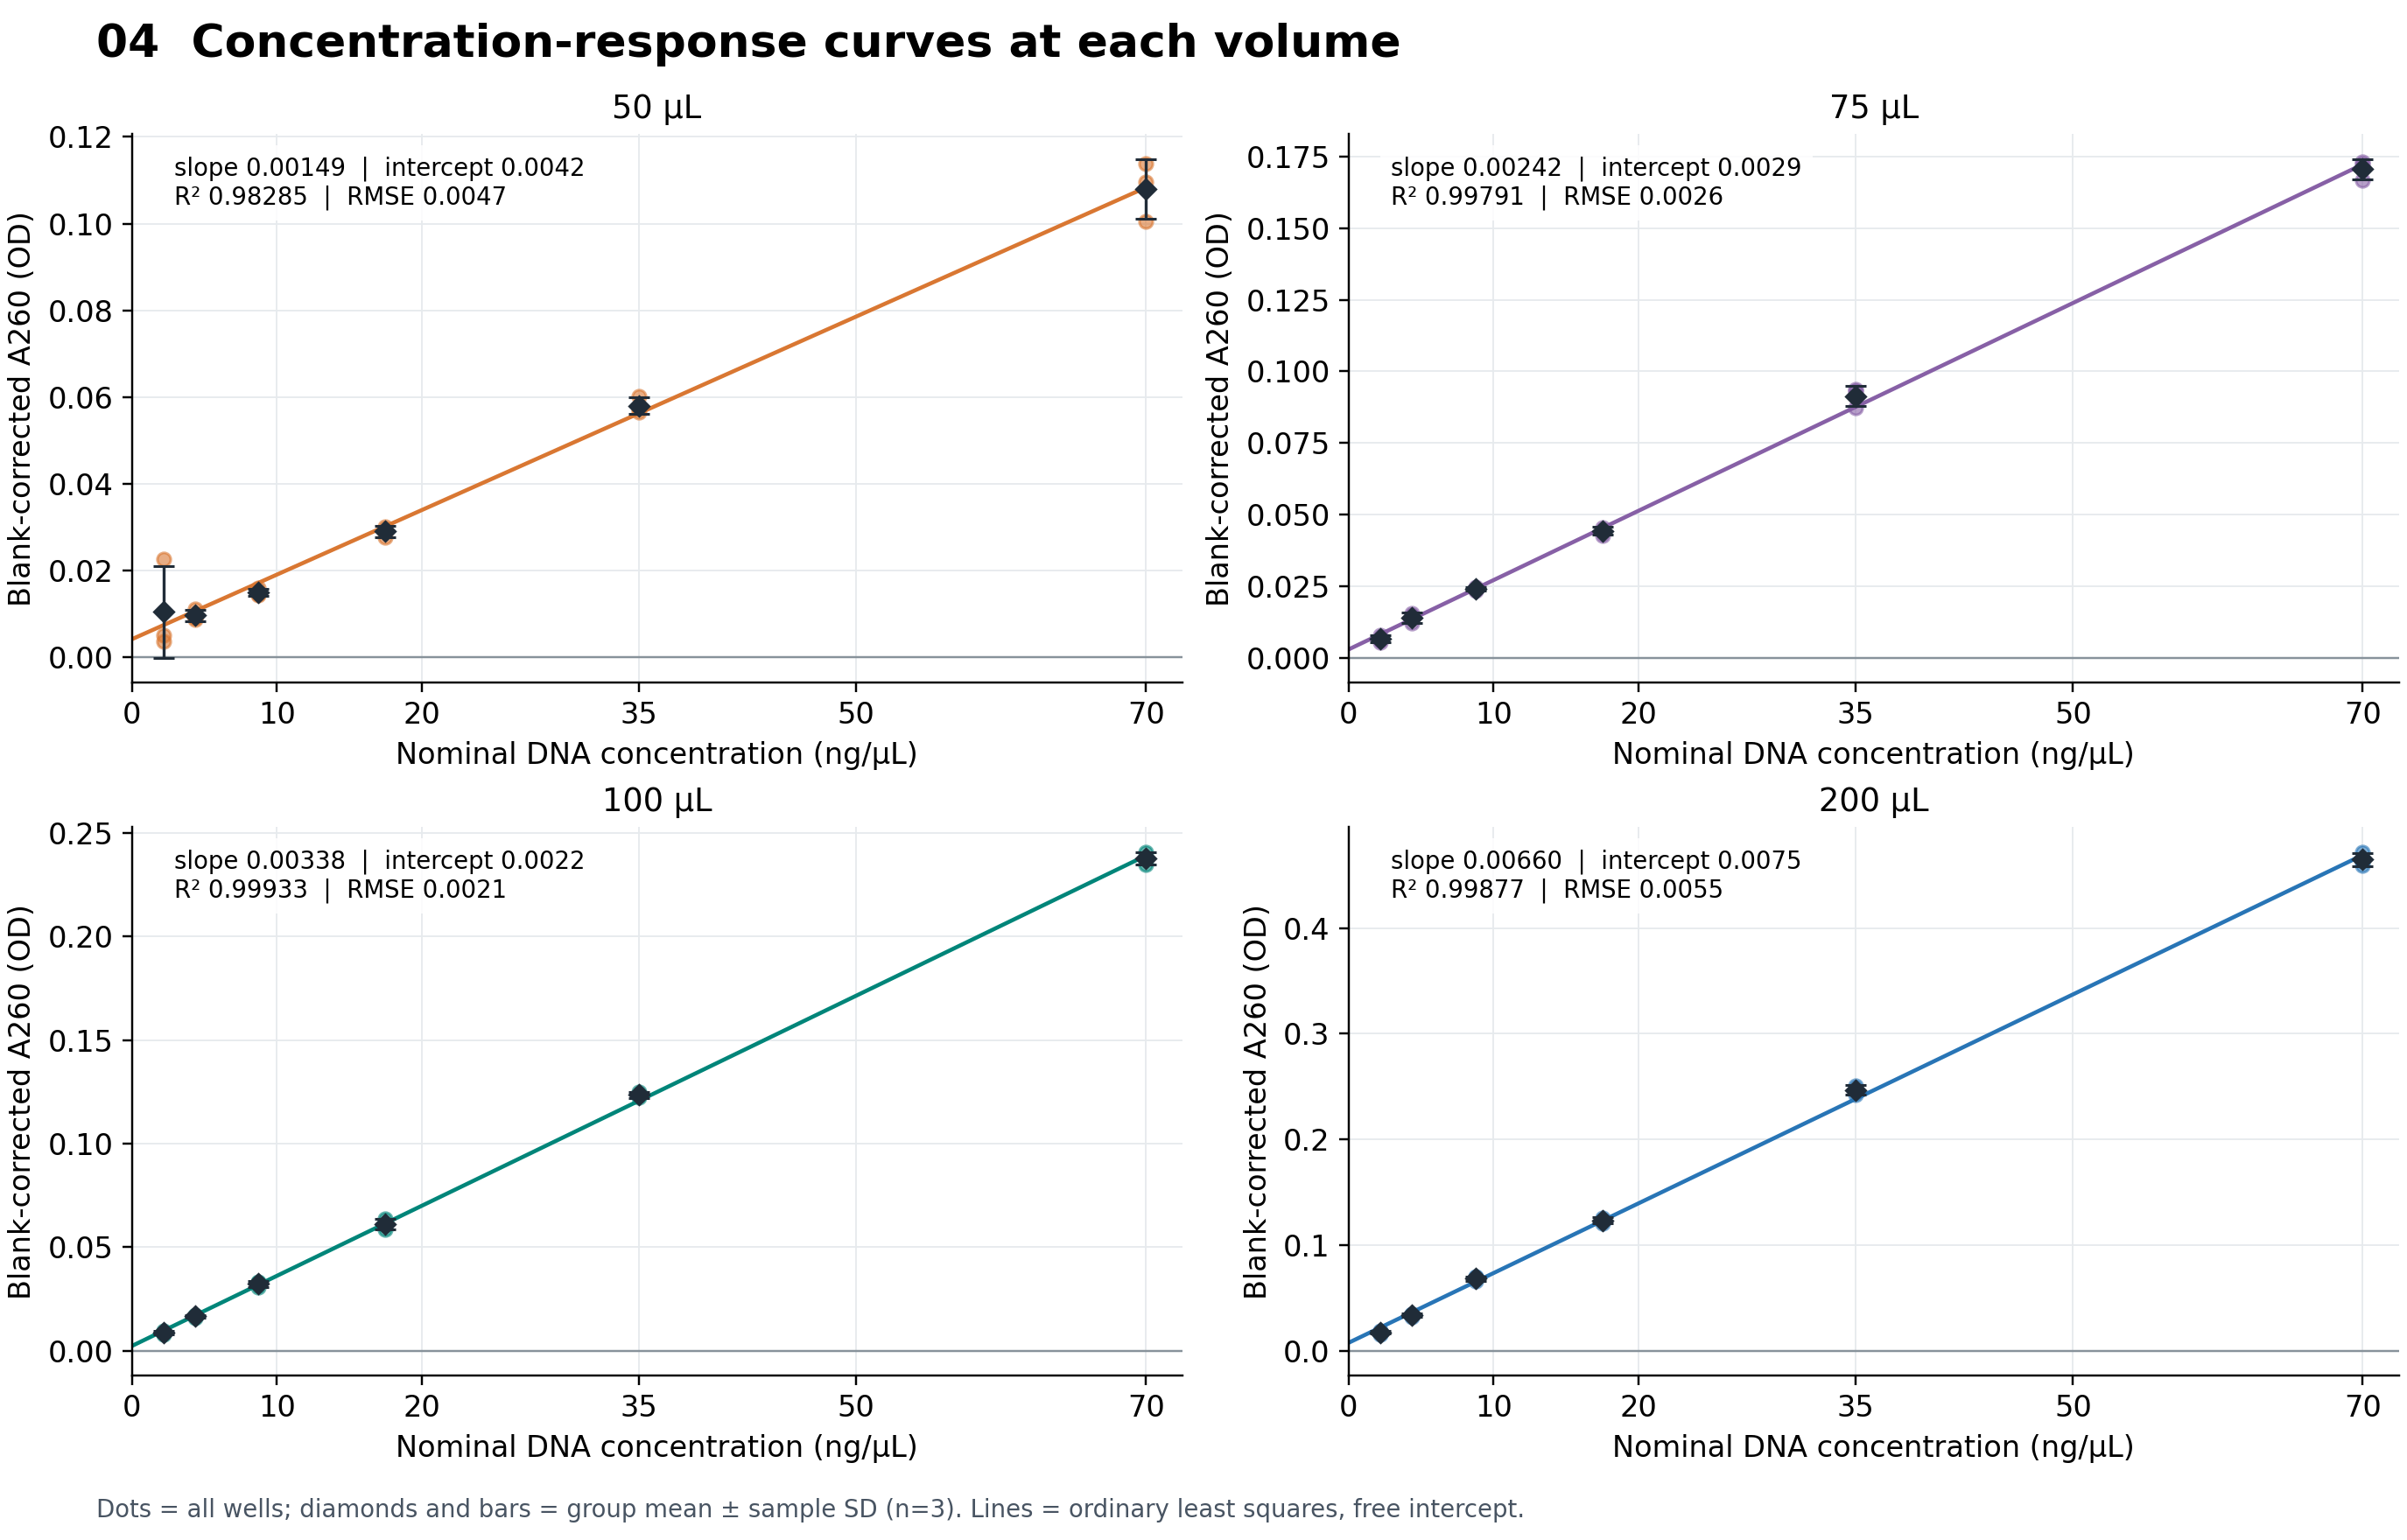

In [9]:
figure = figures[3]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 05  Detecting a signal is different from precise measurement

All three 2.1875 ng/µL wells at each volume exceed the matching 3.3-blank-SD screen. Their corrected CVs are 100.5%, 18.9%, 8.5% and 8.0% as volume increases. Thus a favorable blank-noise ratio at 50 µL does not rescue its inconsistent low-concentration samples. Thresholds are exploratory screens, not validated detection probabilities.

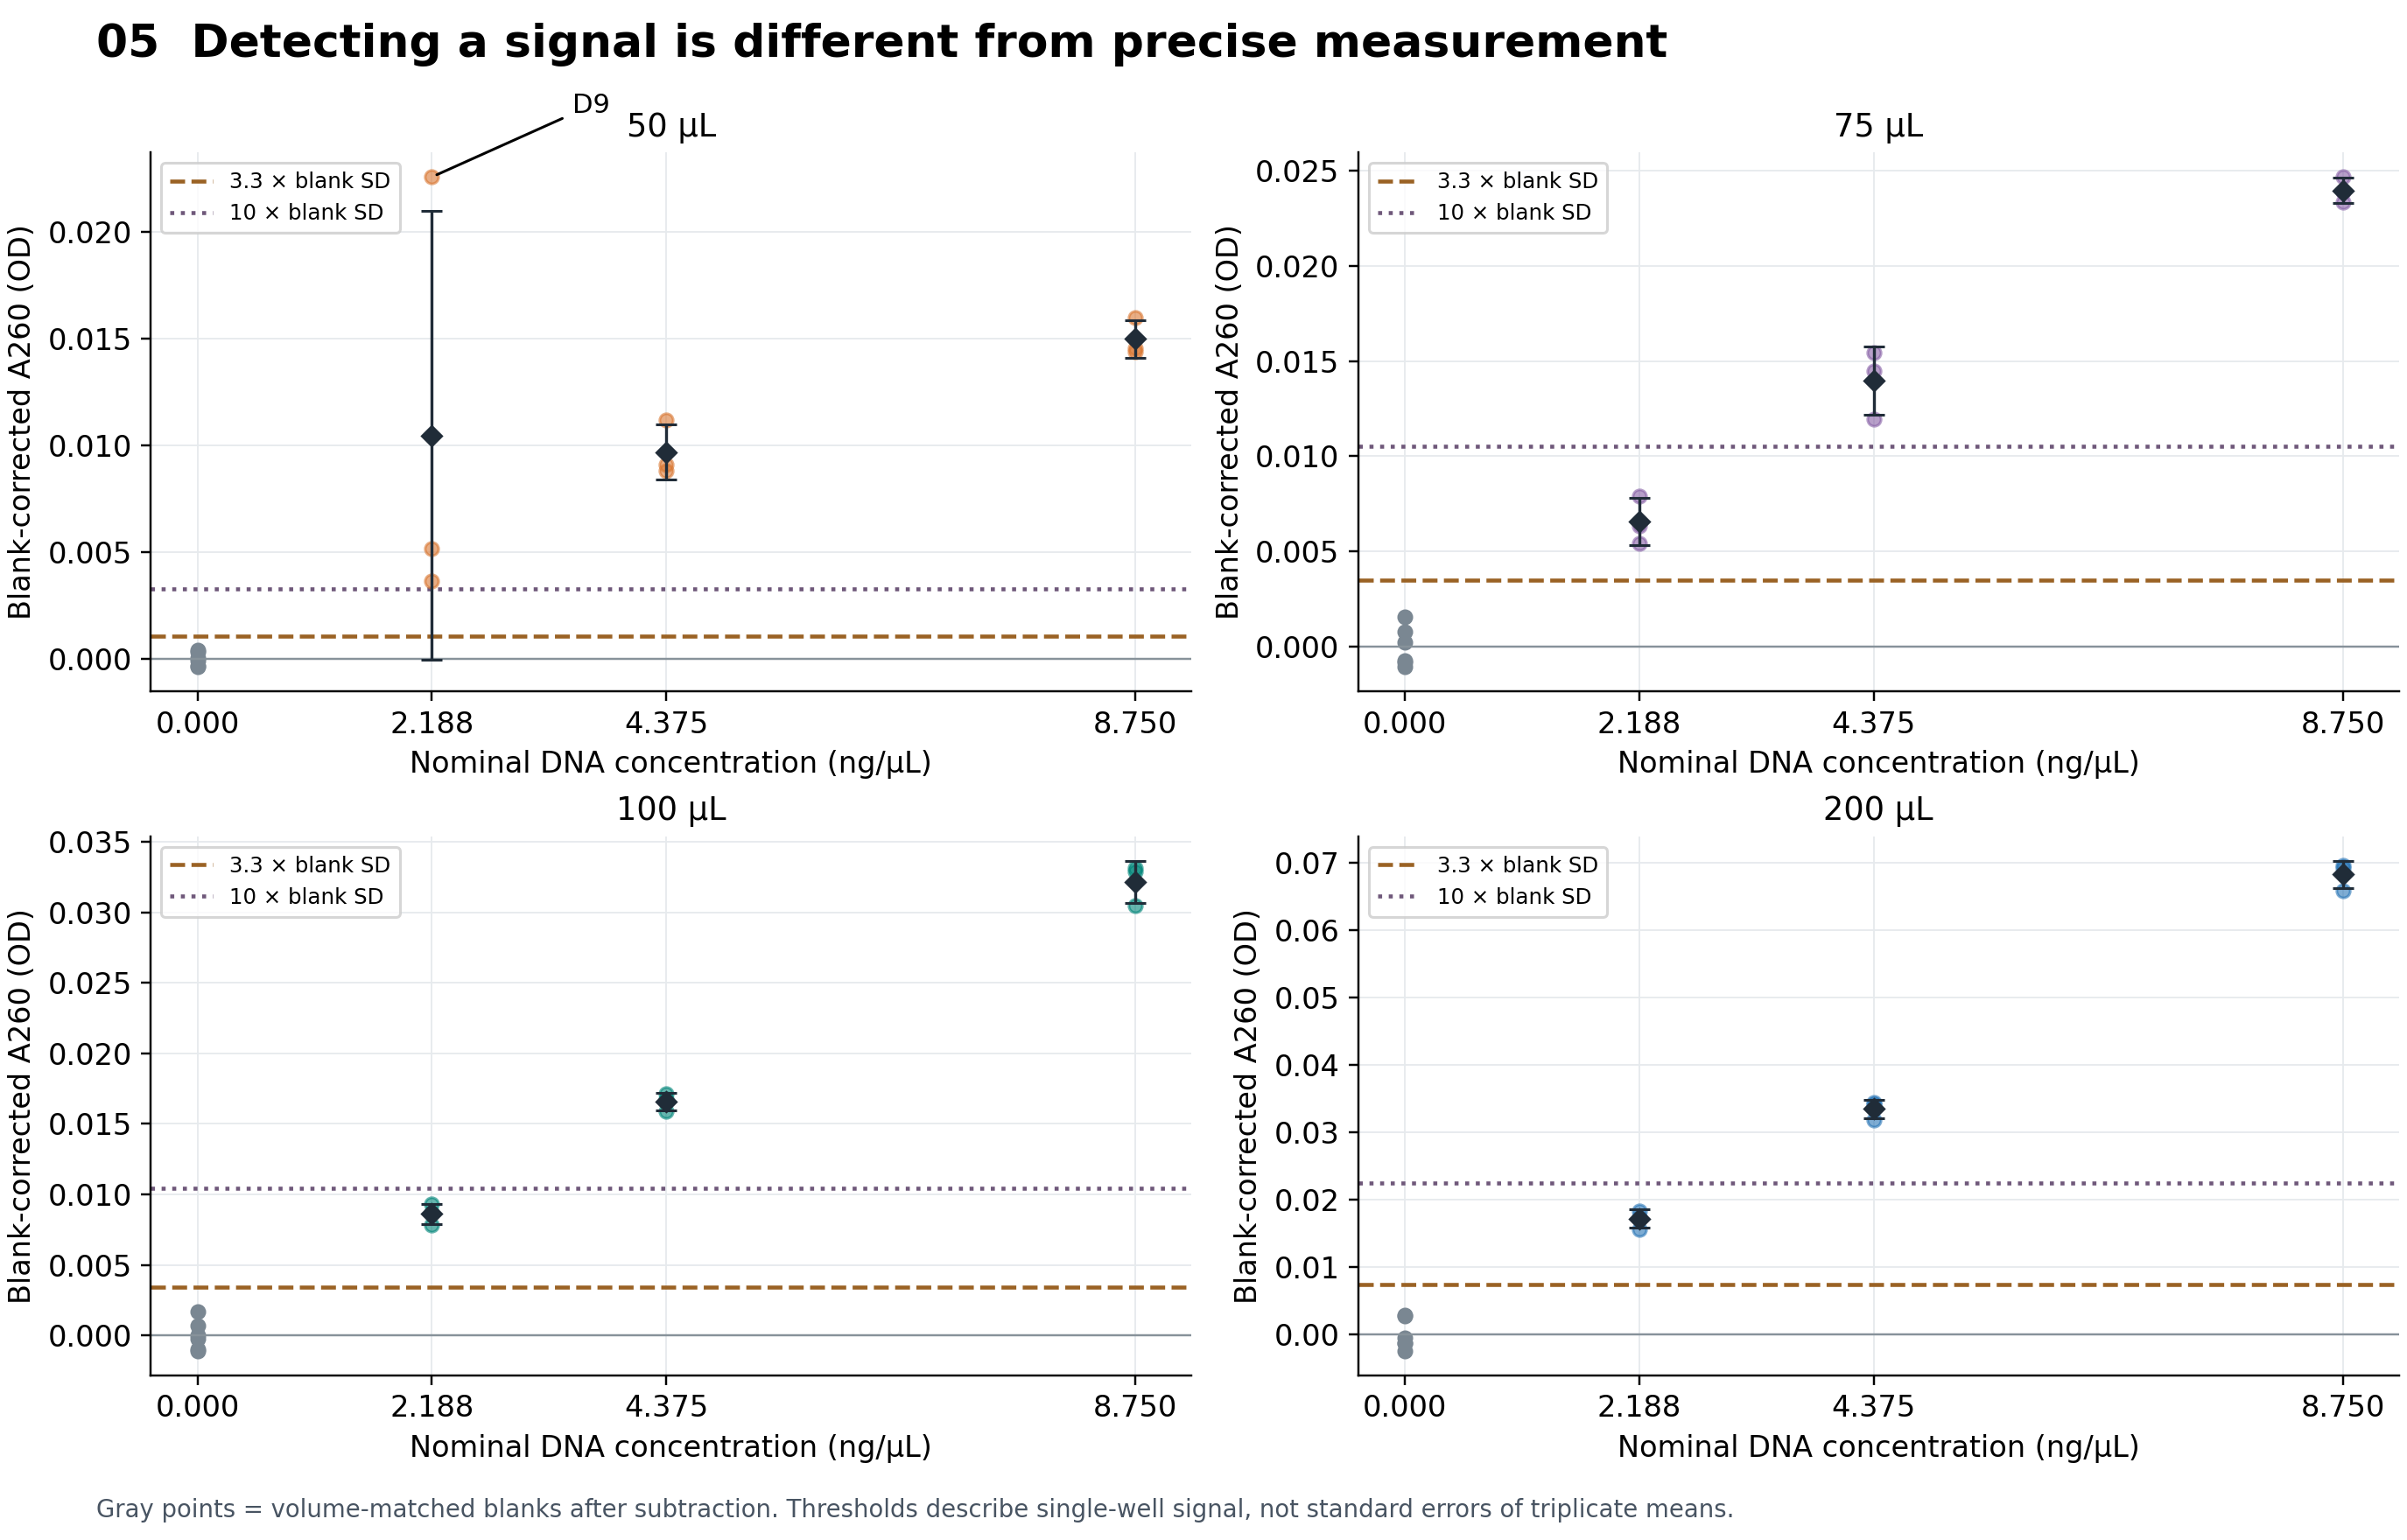

In [10]:
figure = figures[4]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 06  Signal generally increases with well volume

At fixed concentration, larger planned volumes generally give larger corrected absorbance. The lowest concentration is disrupted by the elevated D9 result at 50 µL. At 2.1875 ng/µL, moving from 100 to 200 µL nearly doubles mean signal, but blank variability also increases, so signal gain alone is not a detection-limit improvement.

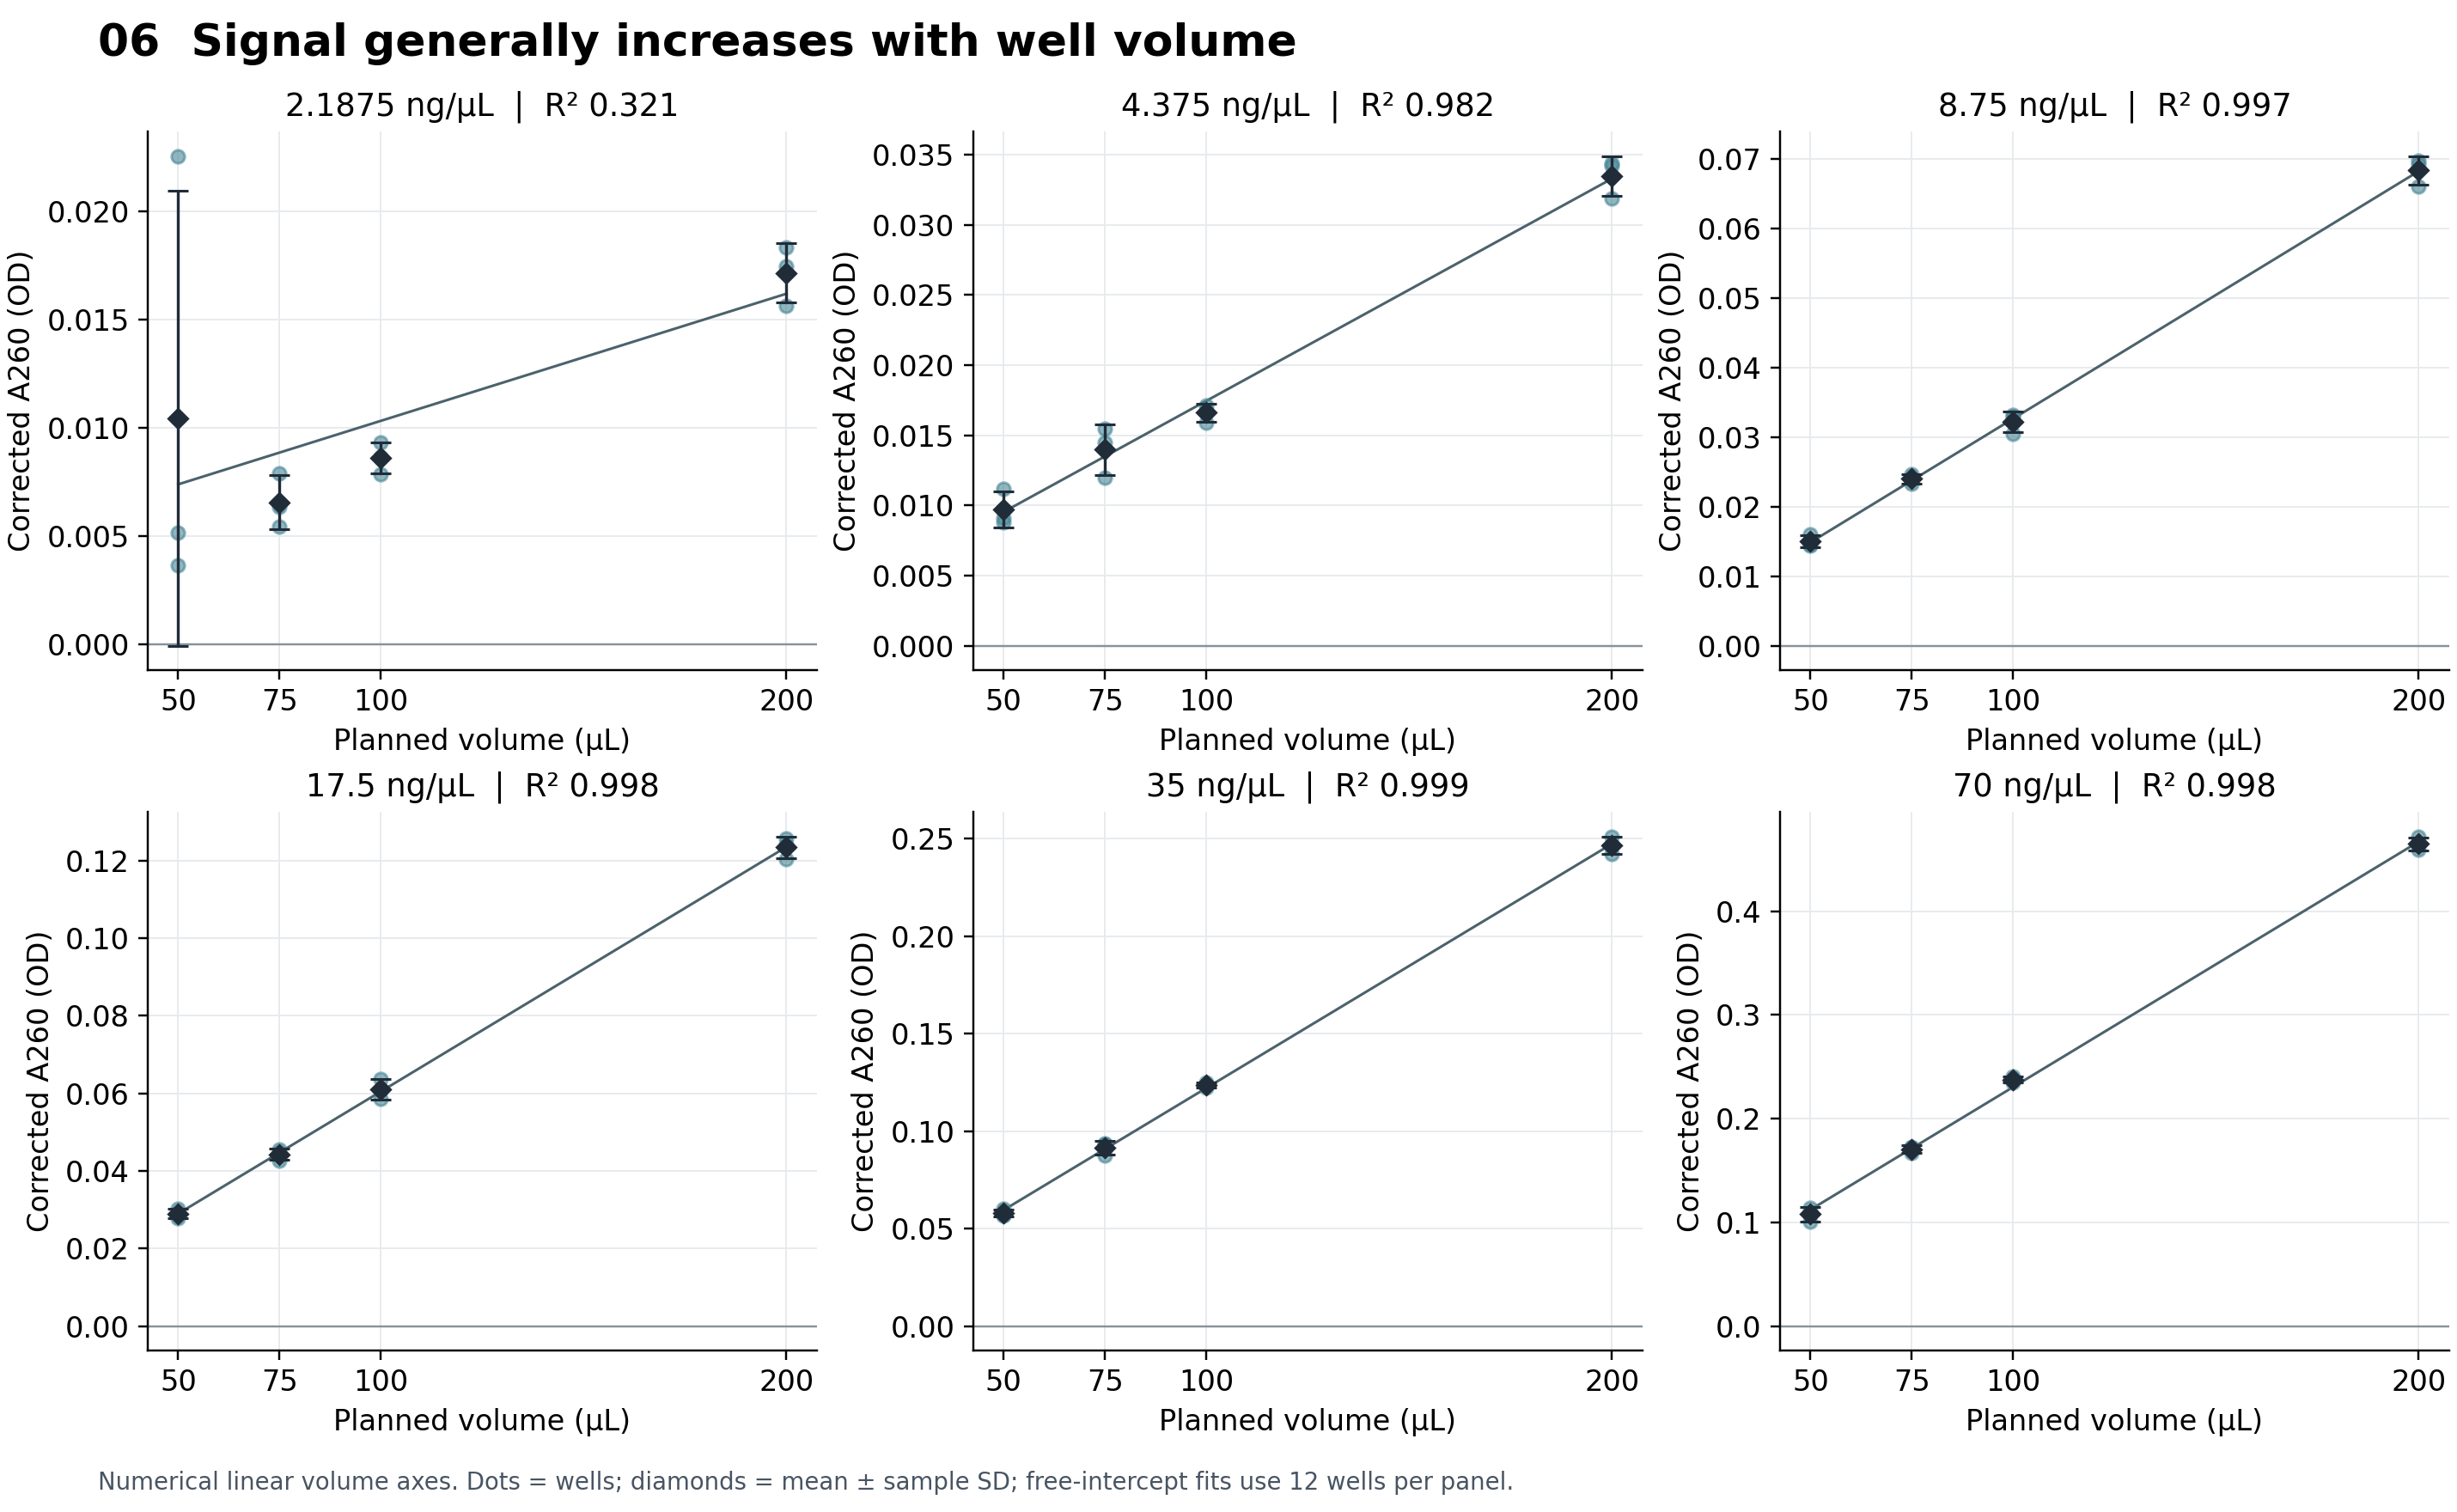

In [11]:
figure = figures[5]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 07  Precision favors 100 µL at the lowest tested concentration

At 100 and 200 µL, all six concentrations have within-condition corrected CV below 10%. At 75 µL, 2.1875 and 4.375 ng/µL have CVs of 18.9% and 12.9%. At 50 µL, CV is below 10% from 8.75 to 70 ng/µL, but fails badly at 2.1875 ng/µL. These three-well CVs measure within-plate repeatability, not dilution accuracy or between-day precision.

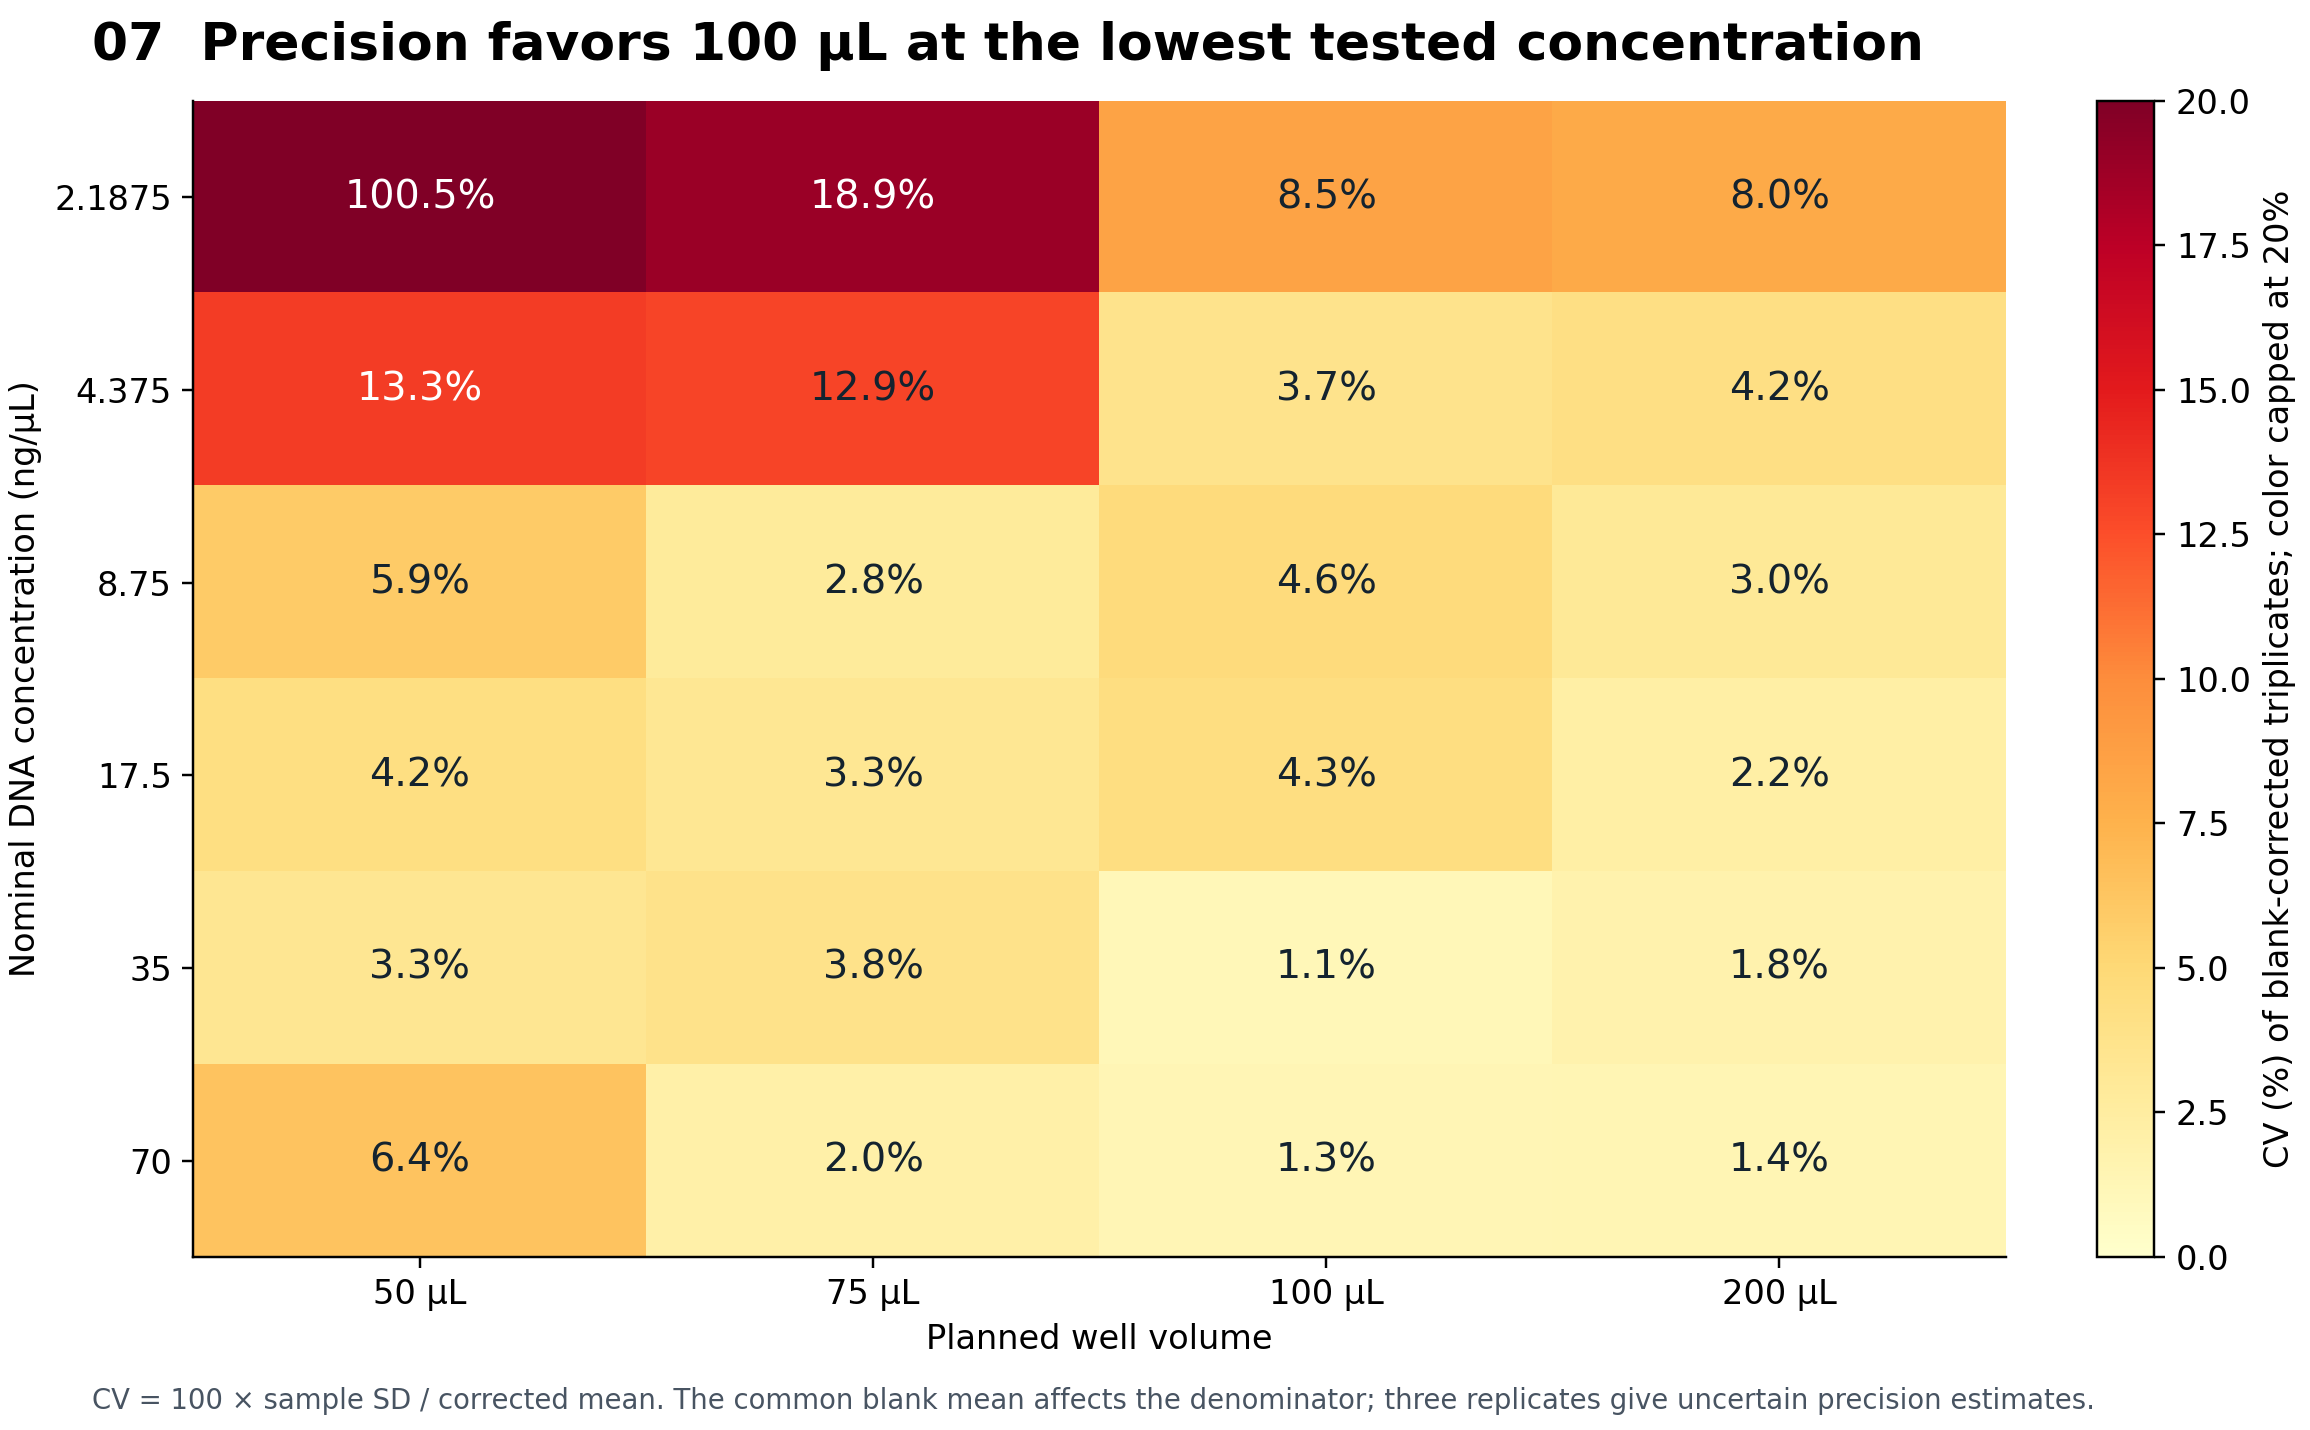

In [12]:
figure = figures[6]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 08  Blank noise and sample precision must be considered together

The 50 µL, 2.1875 ng/µL mean is 31.7 blank SD above zero, yet its CV is 100.5%. In contrast, 100 µL gives a smaller ratio of 8.24 but much tighter samples. The blank-noise ratio is not instrument signal-to-noise and is not a substitute for repeatable sample results or accuracy validation.

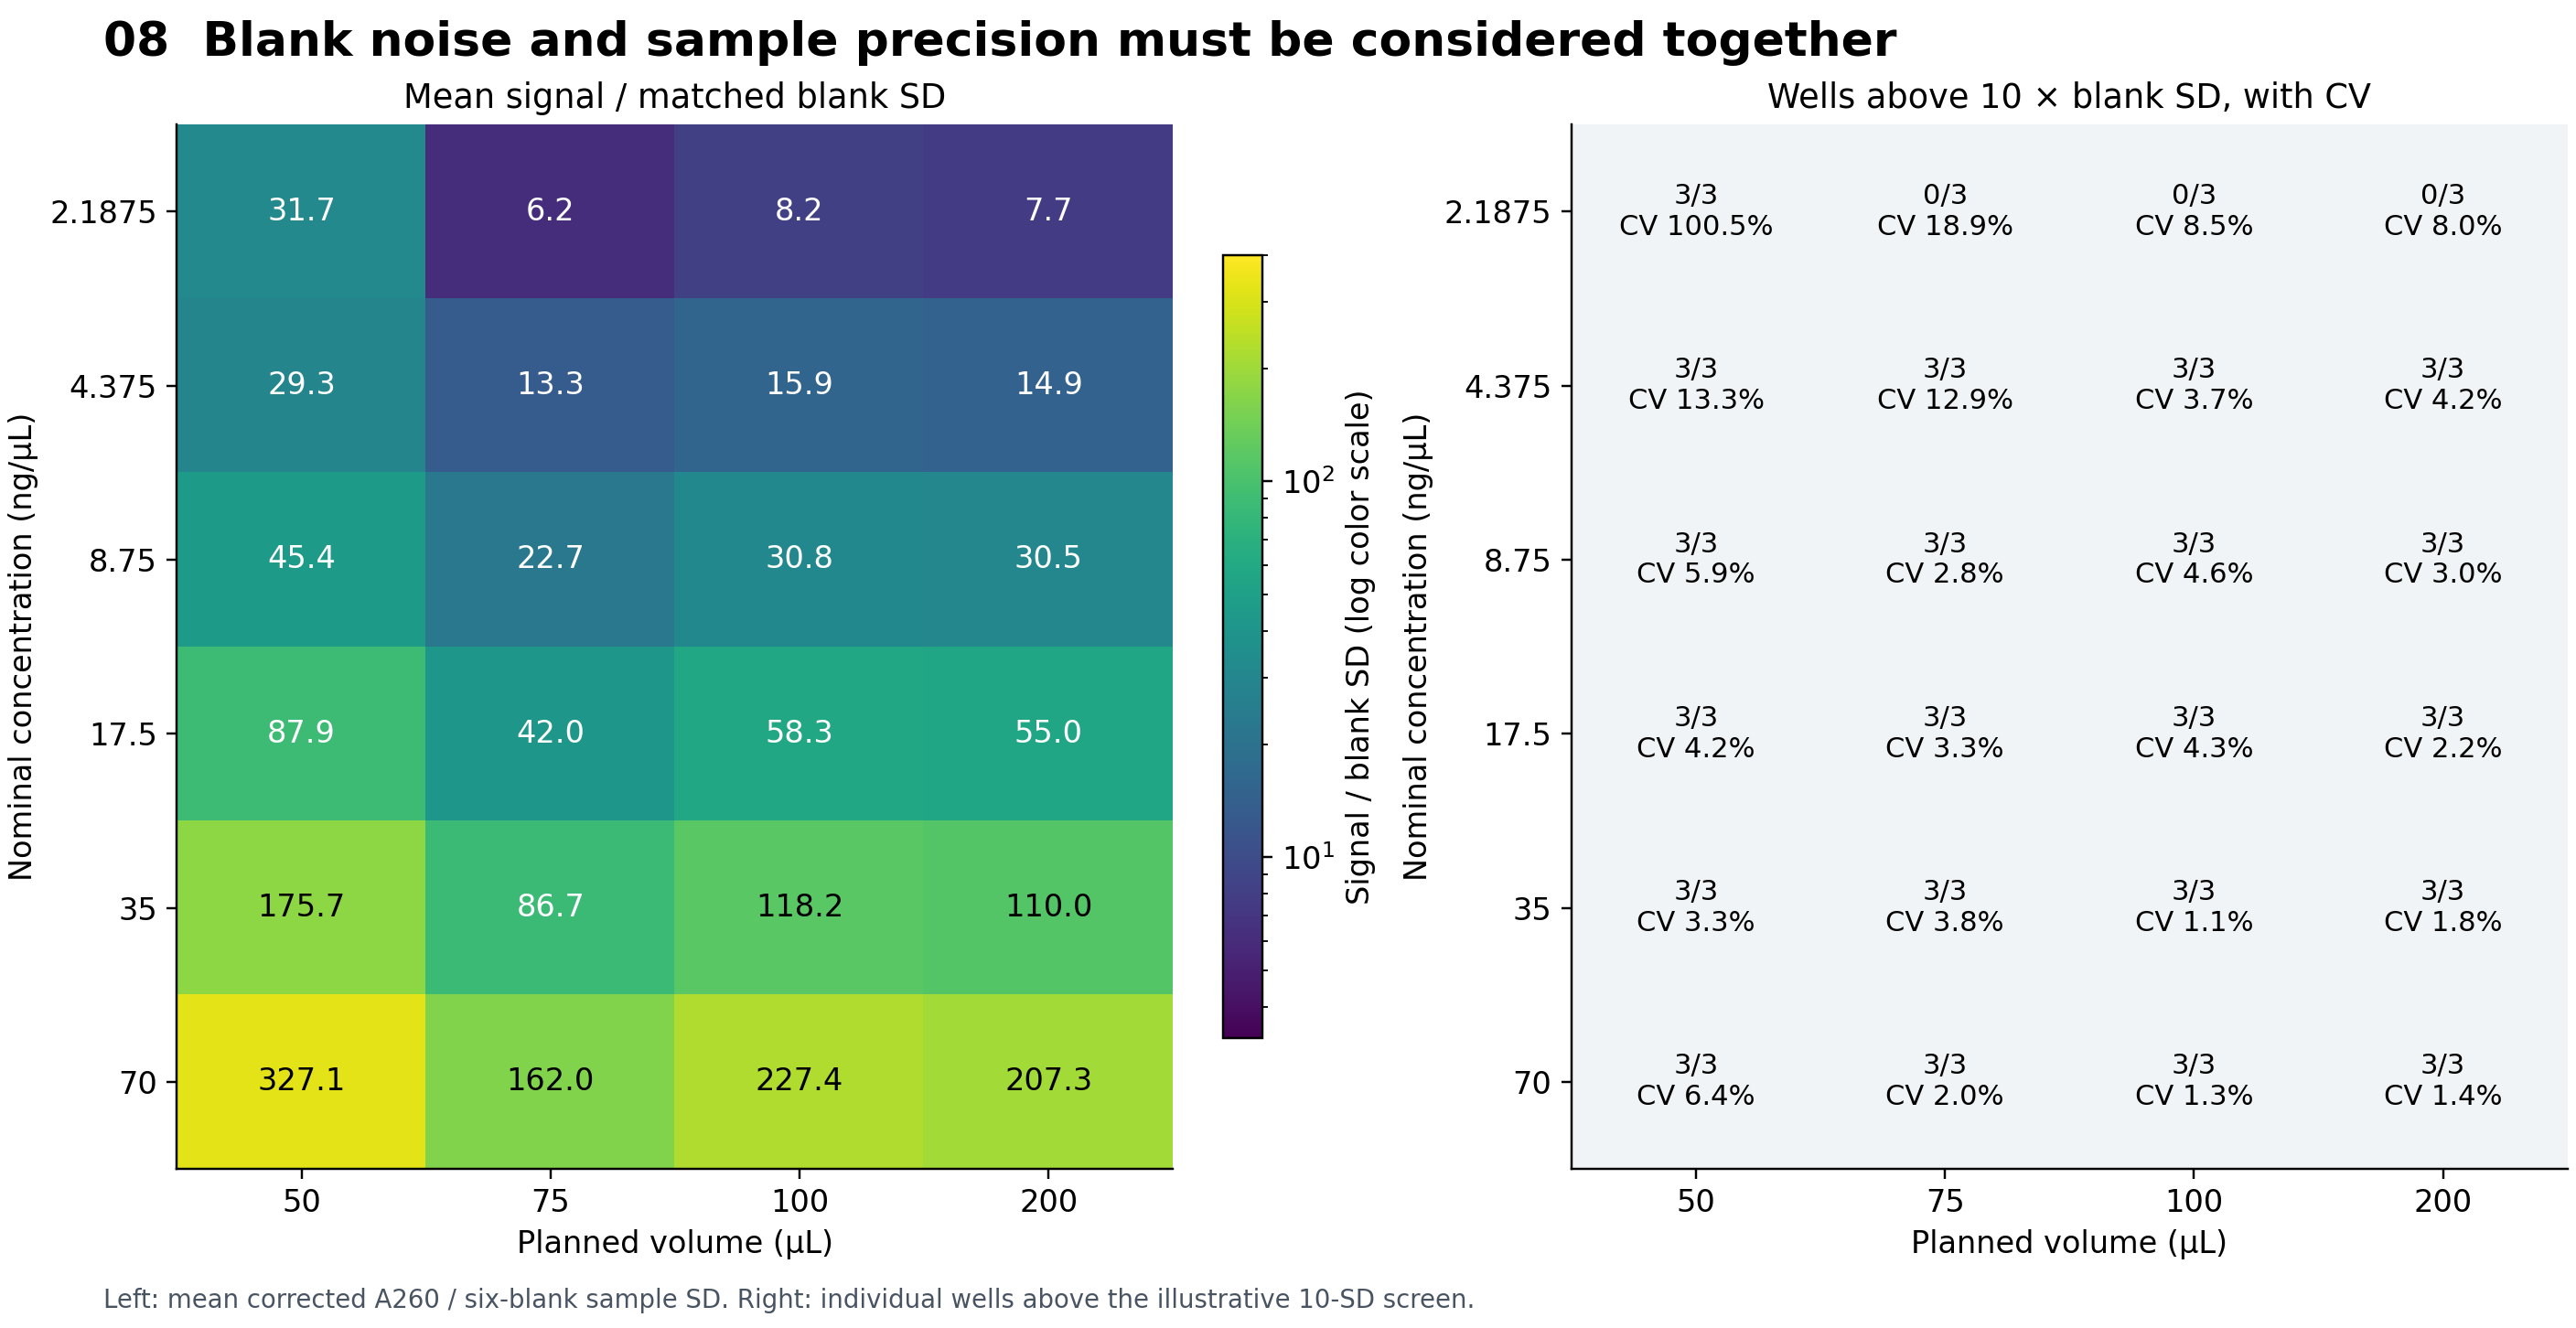

In [13]:
figure = figures[7]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 09  Noise-based limits are hypotheses to validate

Full-range blank-noise DL estimates are approximately 0.73, 1.44, 1.02 and 1.12 ng/µL; QL estimates are 2.22, 4.35, 3.09 and 3.40 ng/µL. The apparently favorable 50 µL DL conflicts with its low-end sample variability. The fixed 2.1875-17.5 ng/µL fits show range sensitivity. Values below 2.1875 ng/µL were not tested, and neither these intervals nor high R² establish a validated limit.

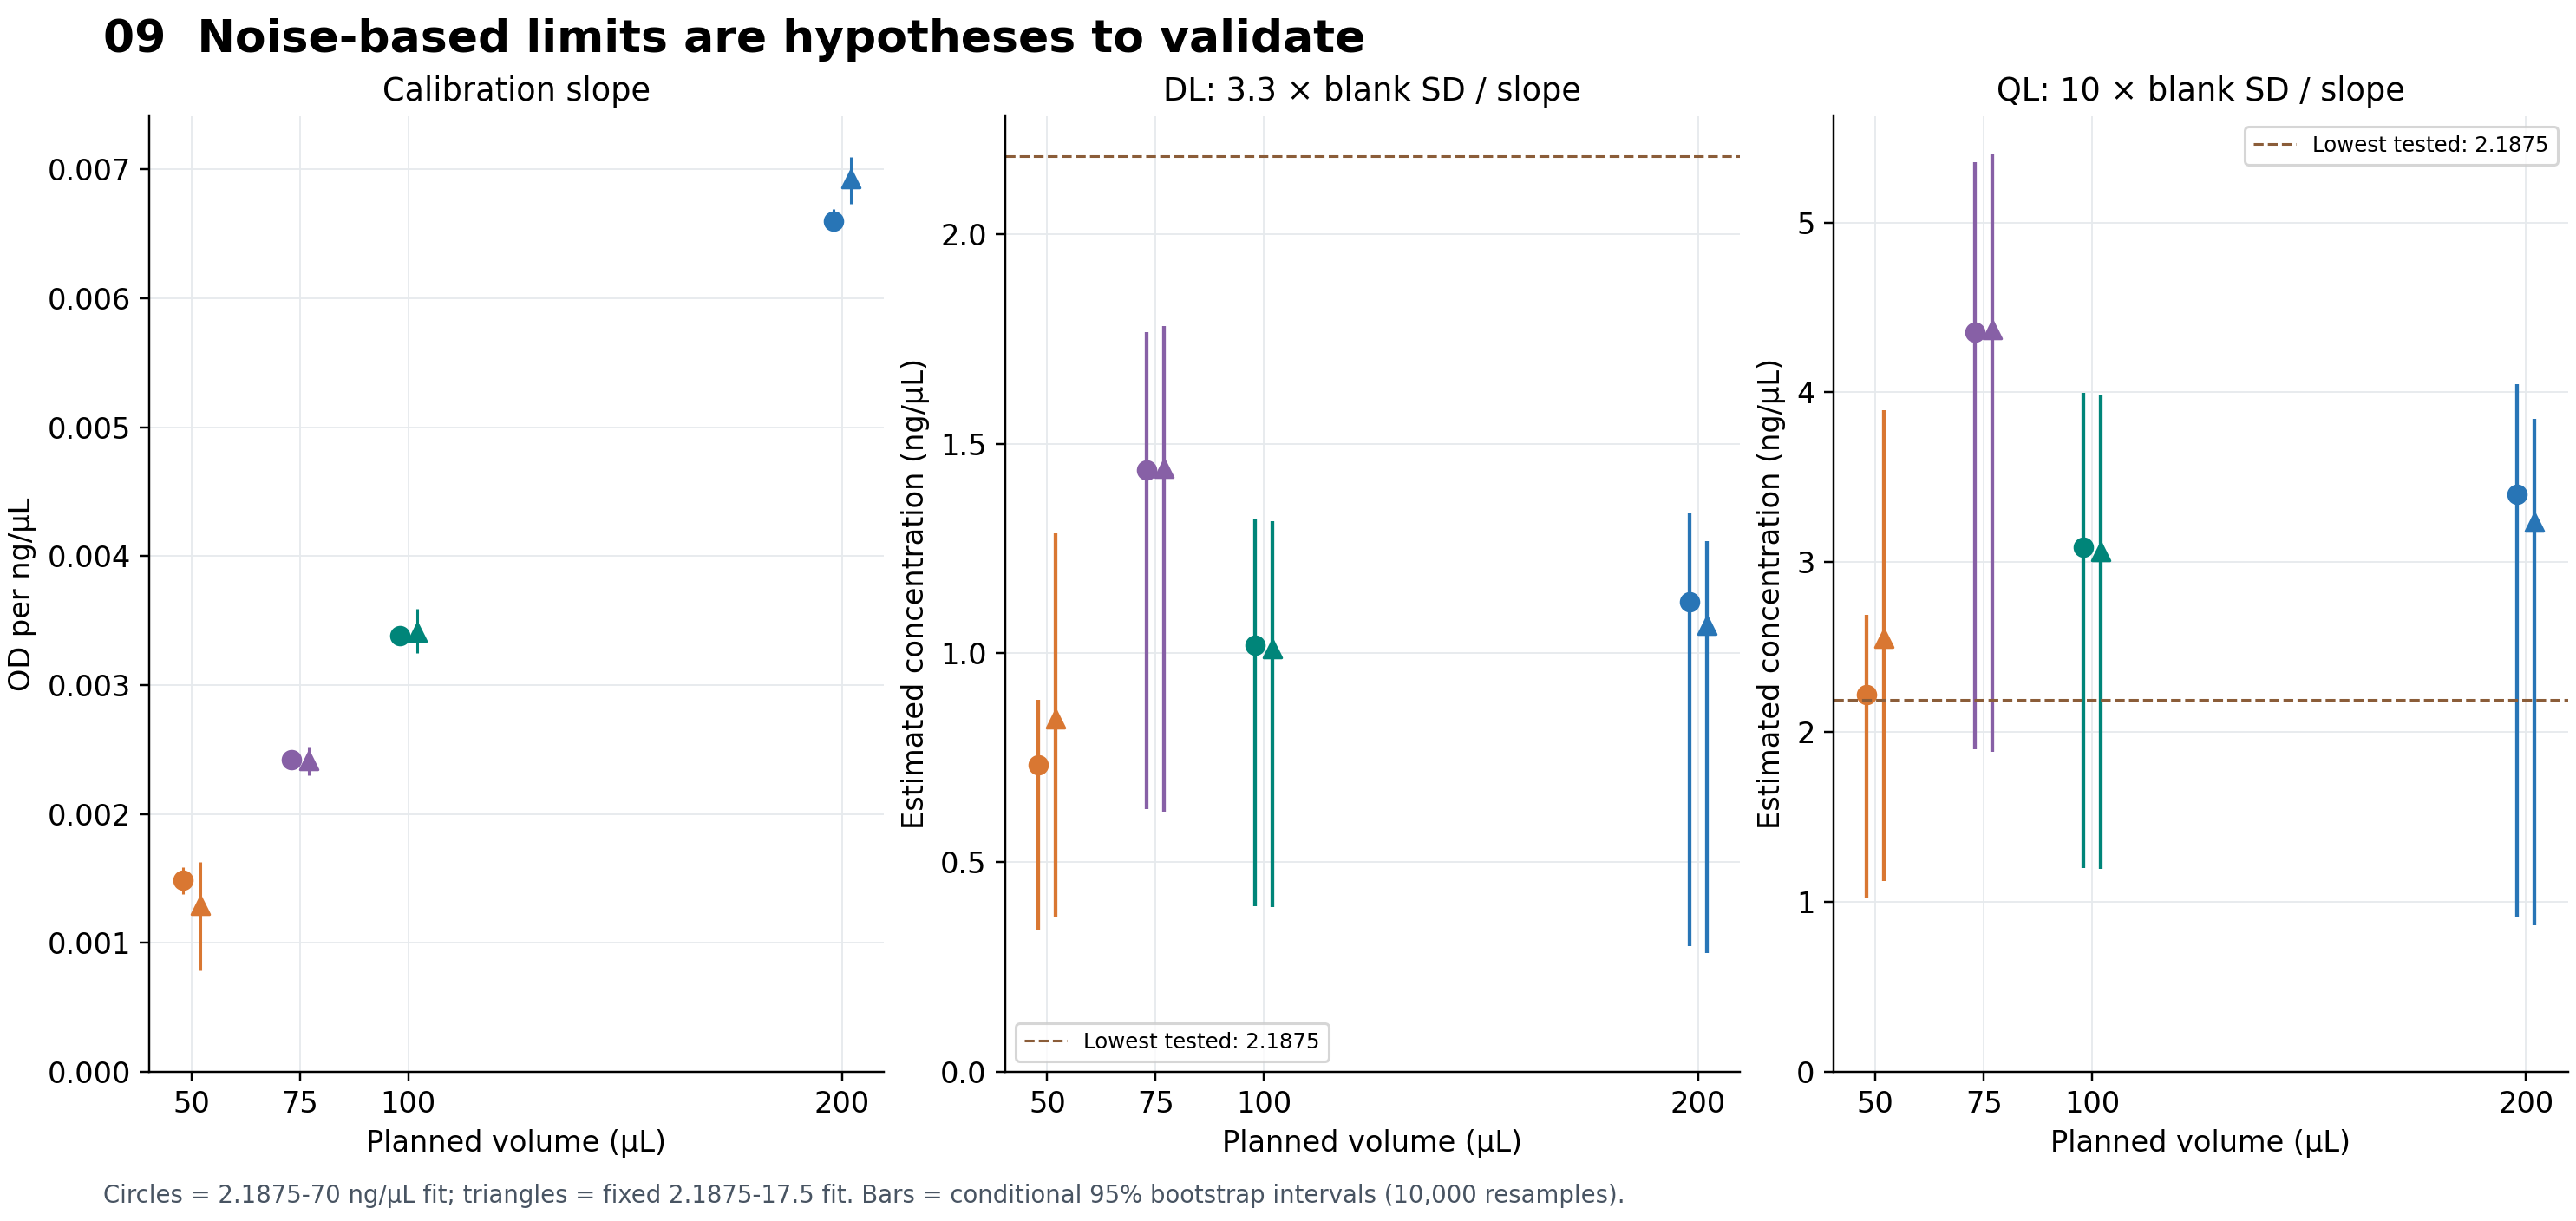

In [14]:
figure = figures[8]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 10  Volume normalization diagnoses departures from simple scaling

Most volume-normalized responses are close to the 100 µL reference, particularly at moderate concentrations. The 50 µL, 2.1875 ng/µL point is elevated and uncertain because D9 raises its mean. Dividing by planned volume is a descriptive normalization, not a measured path-length correction or evidence of actual dispensed volume.

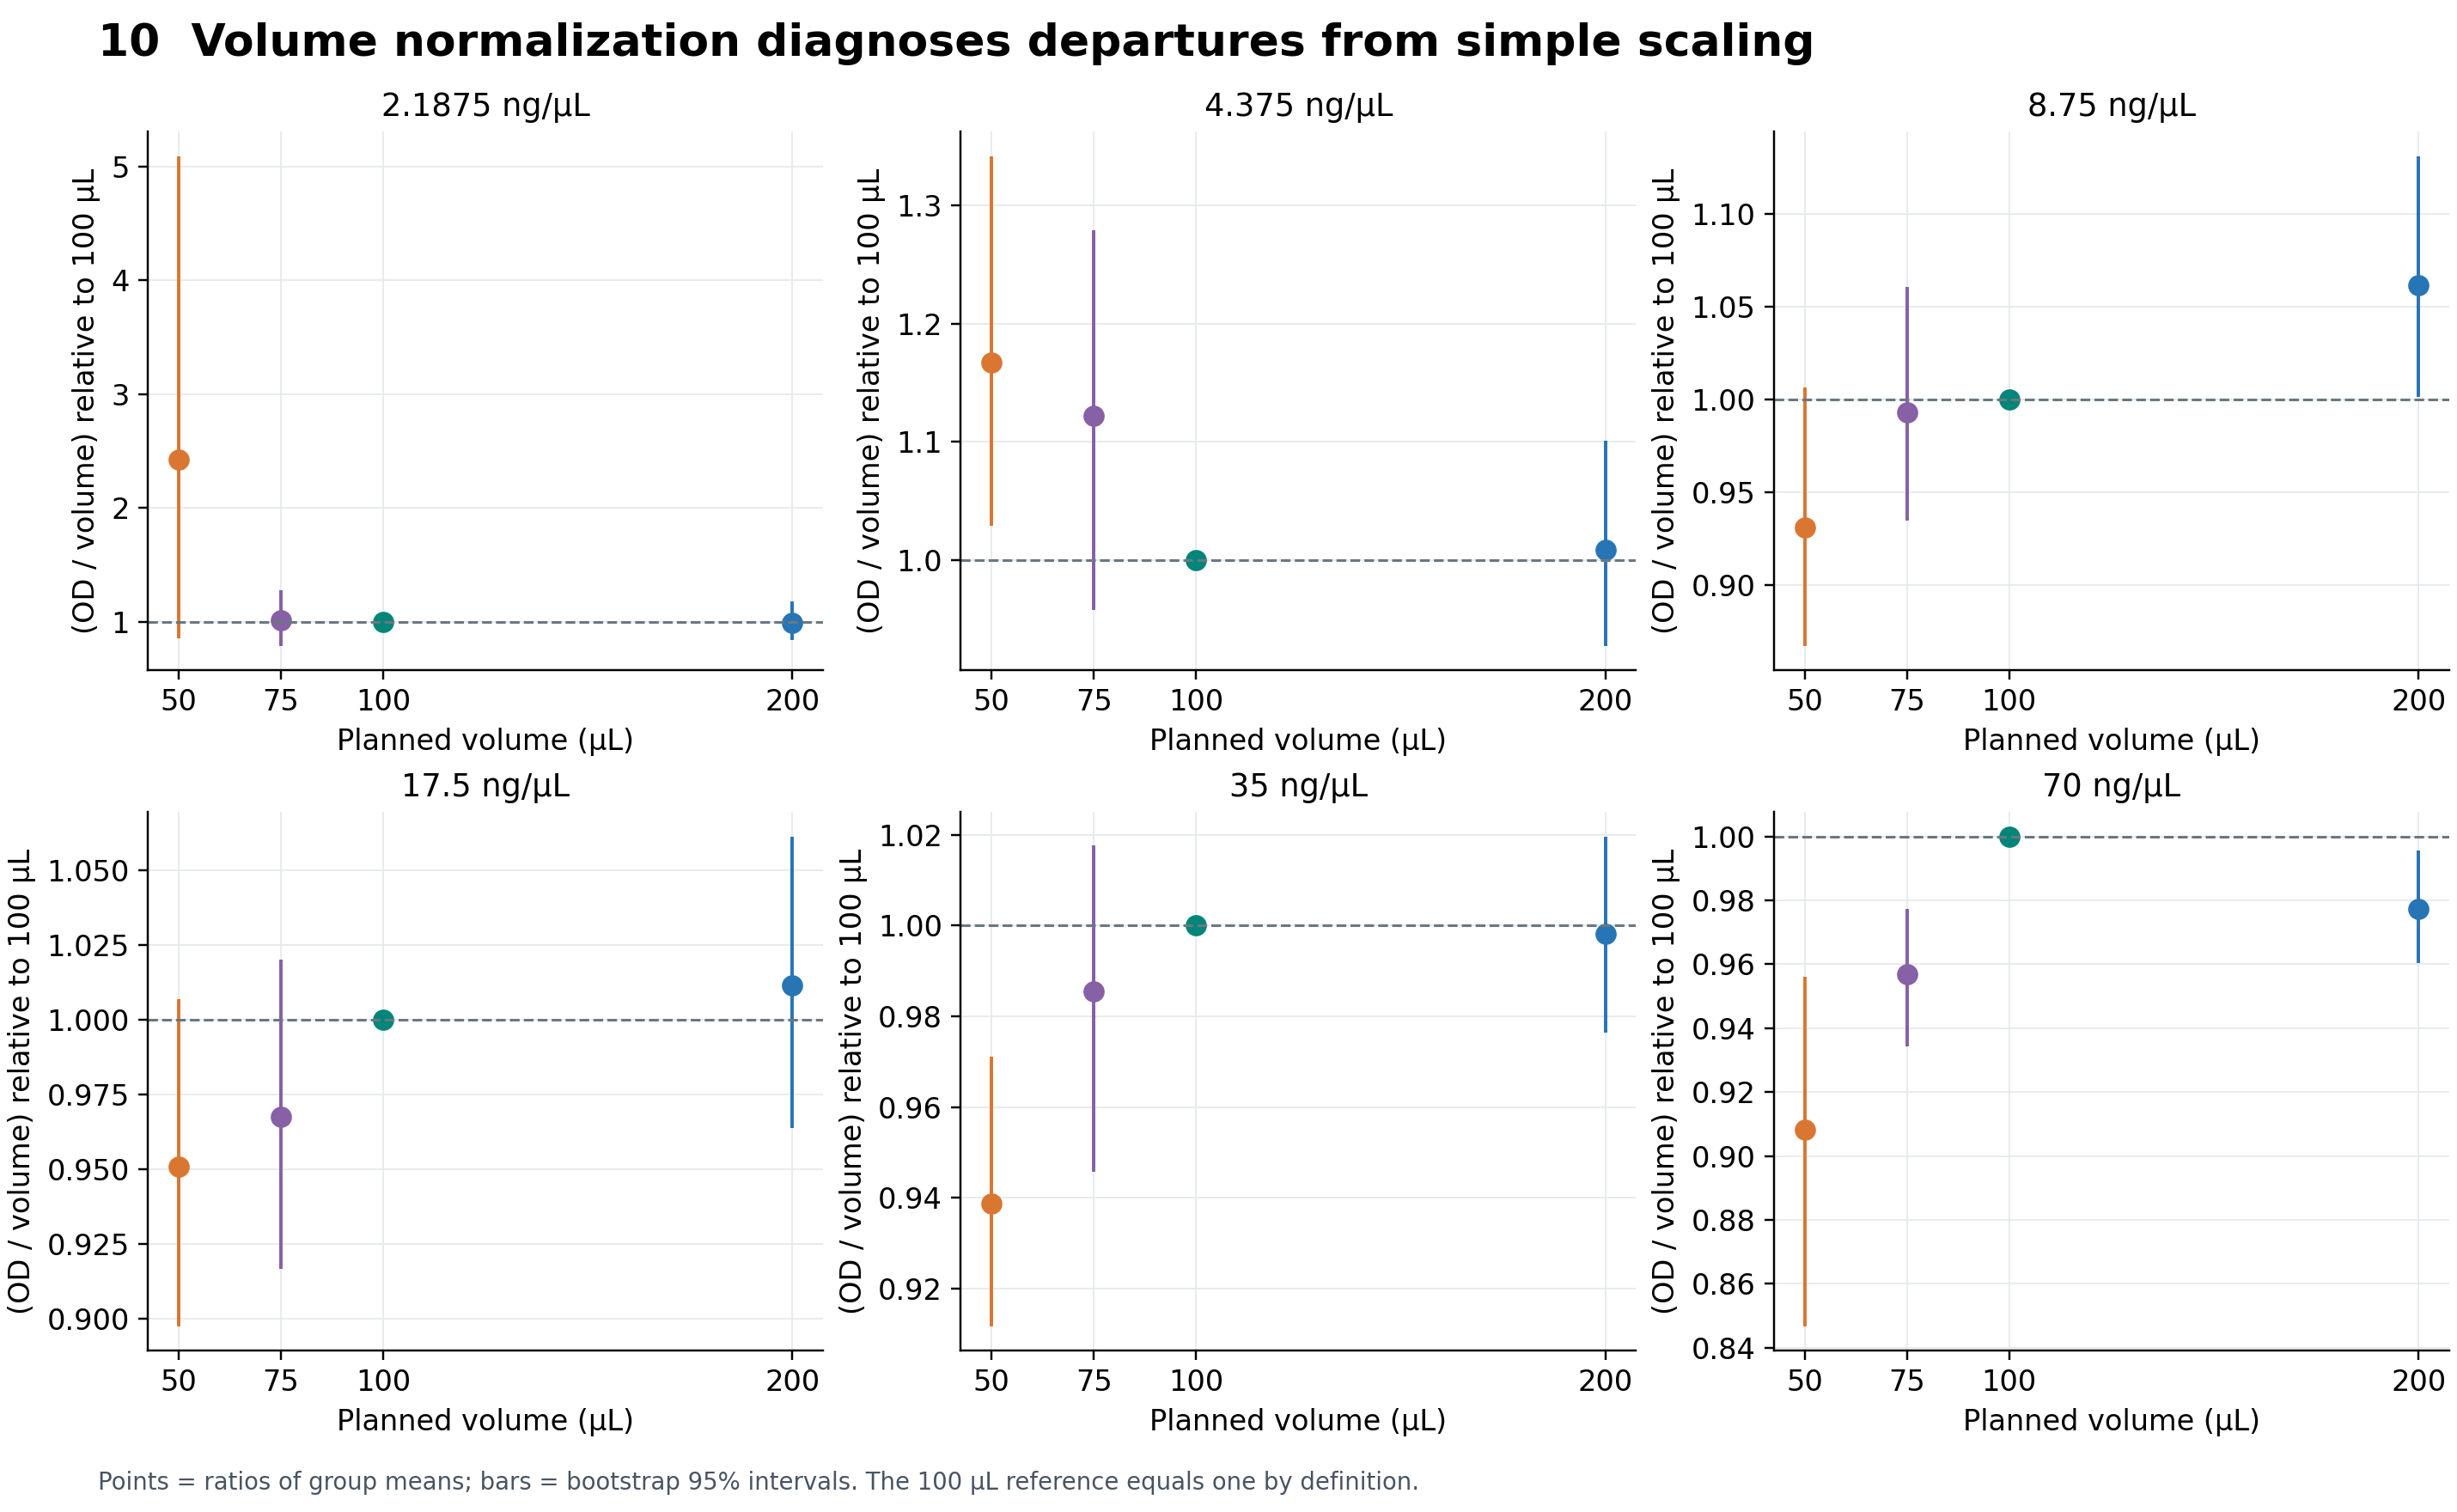

In [15]:
figure = figures[9]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 11  High R² does not rule out systematic departures

Red group means have 95% bootstrap departure intervals that exclude zero. Several conditions depart detectably from their fitted lines despite high R². These are exploratory, unadjusted comparisons based on one plate. They can reflect optical response, dilution error, dispensing differences or isolated wells; they do not isolate a mechanism.

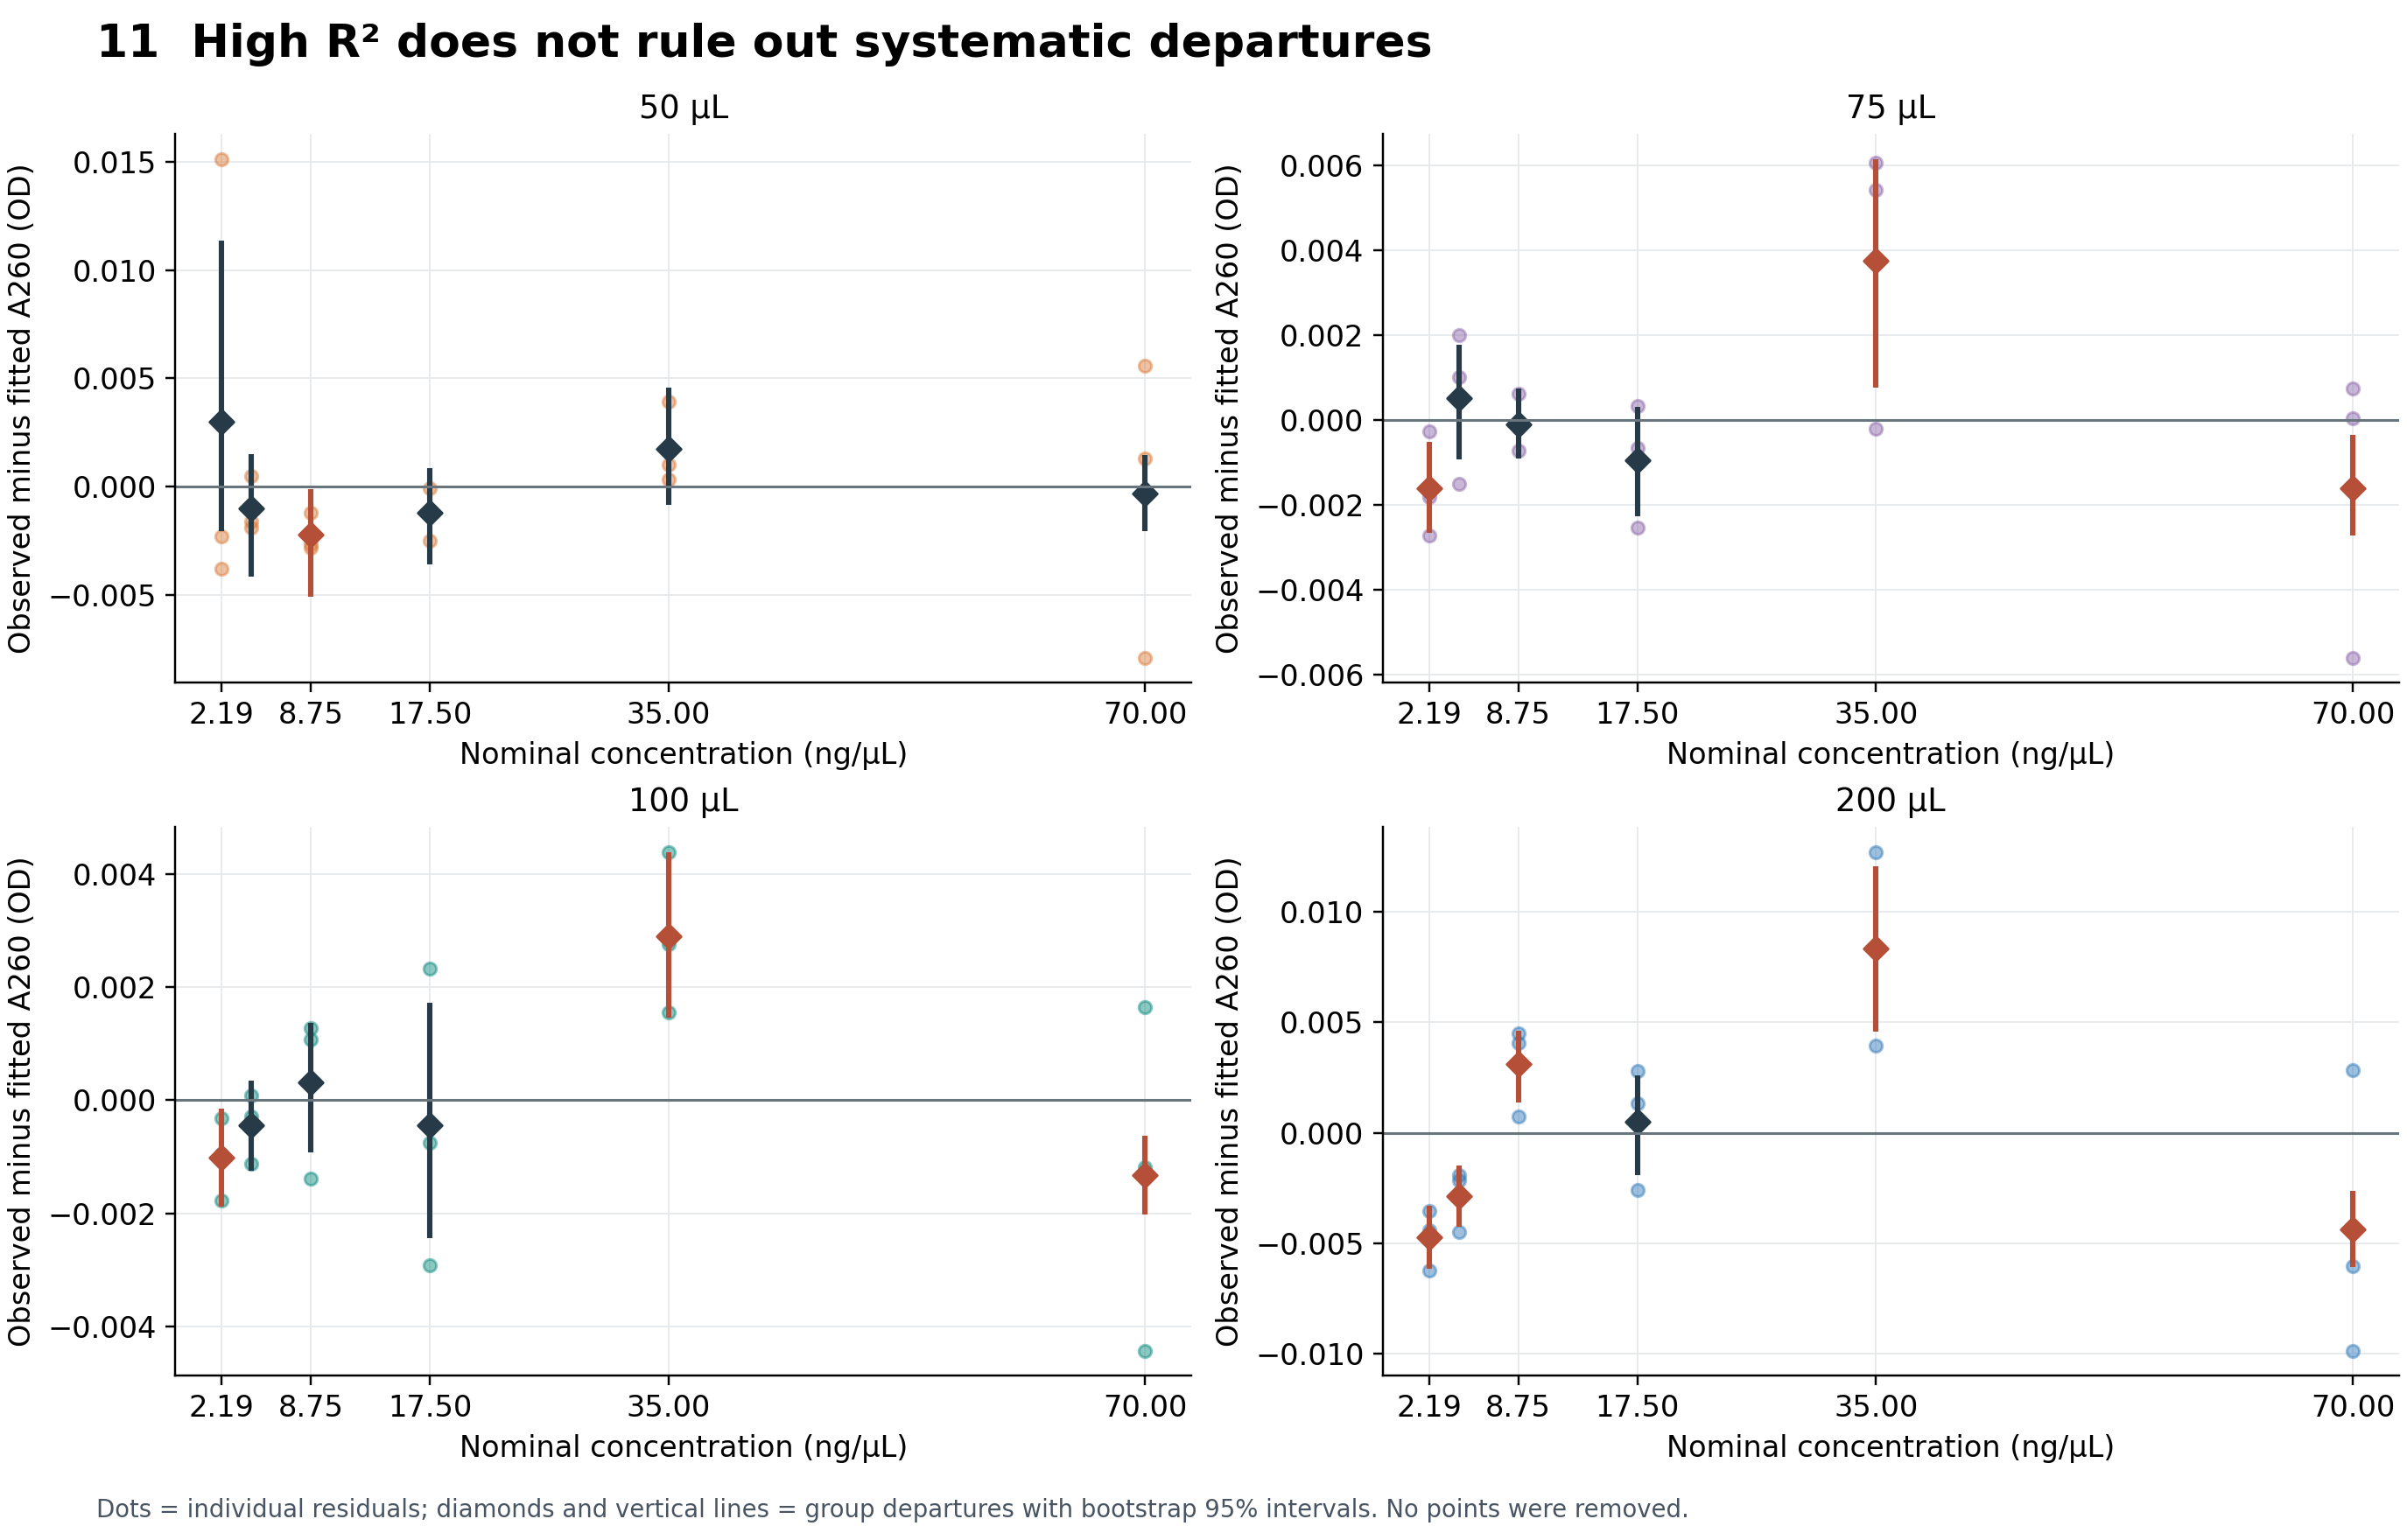

In [16]:
figure = figures[10]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 12  Spatial checks locate influential wells without assigning causes

D9 is conspicuous within its own concentration-volume condition. Spatial residuals also identify the strongest discrepancies elsewhere, but each location has only one observation and variance changes with signal. A single map cannot distinguish a positional optical effect from pipetting, dilution or a bubble. All wells remain included.

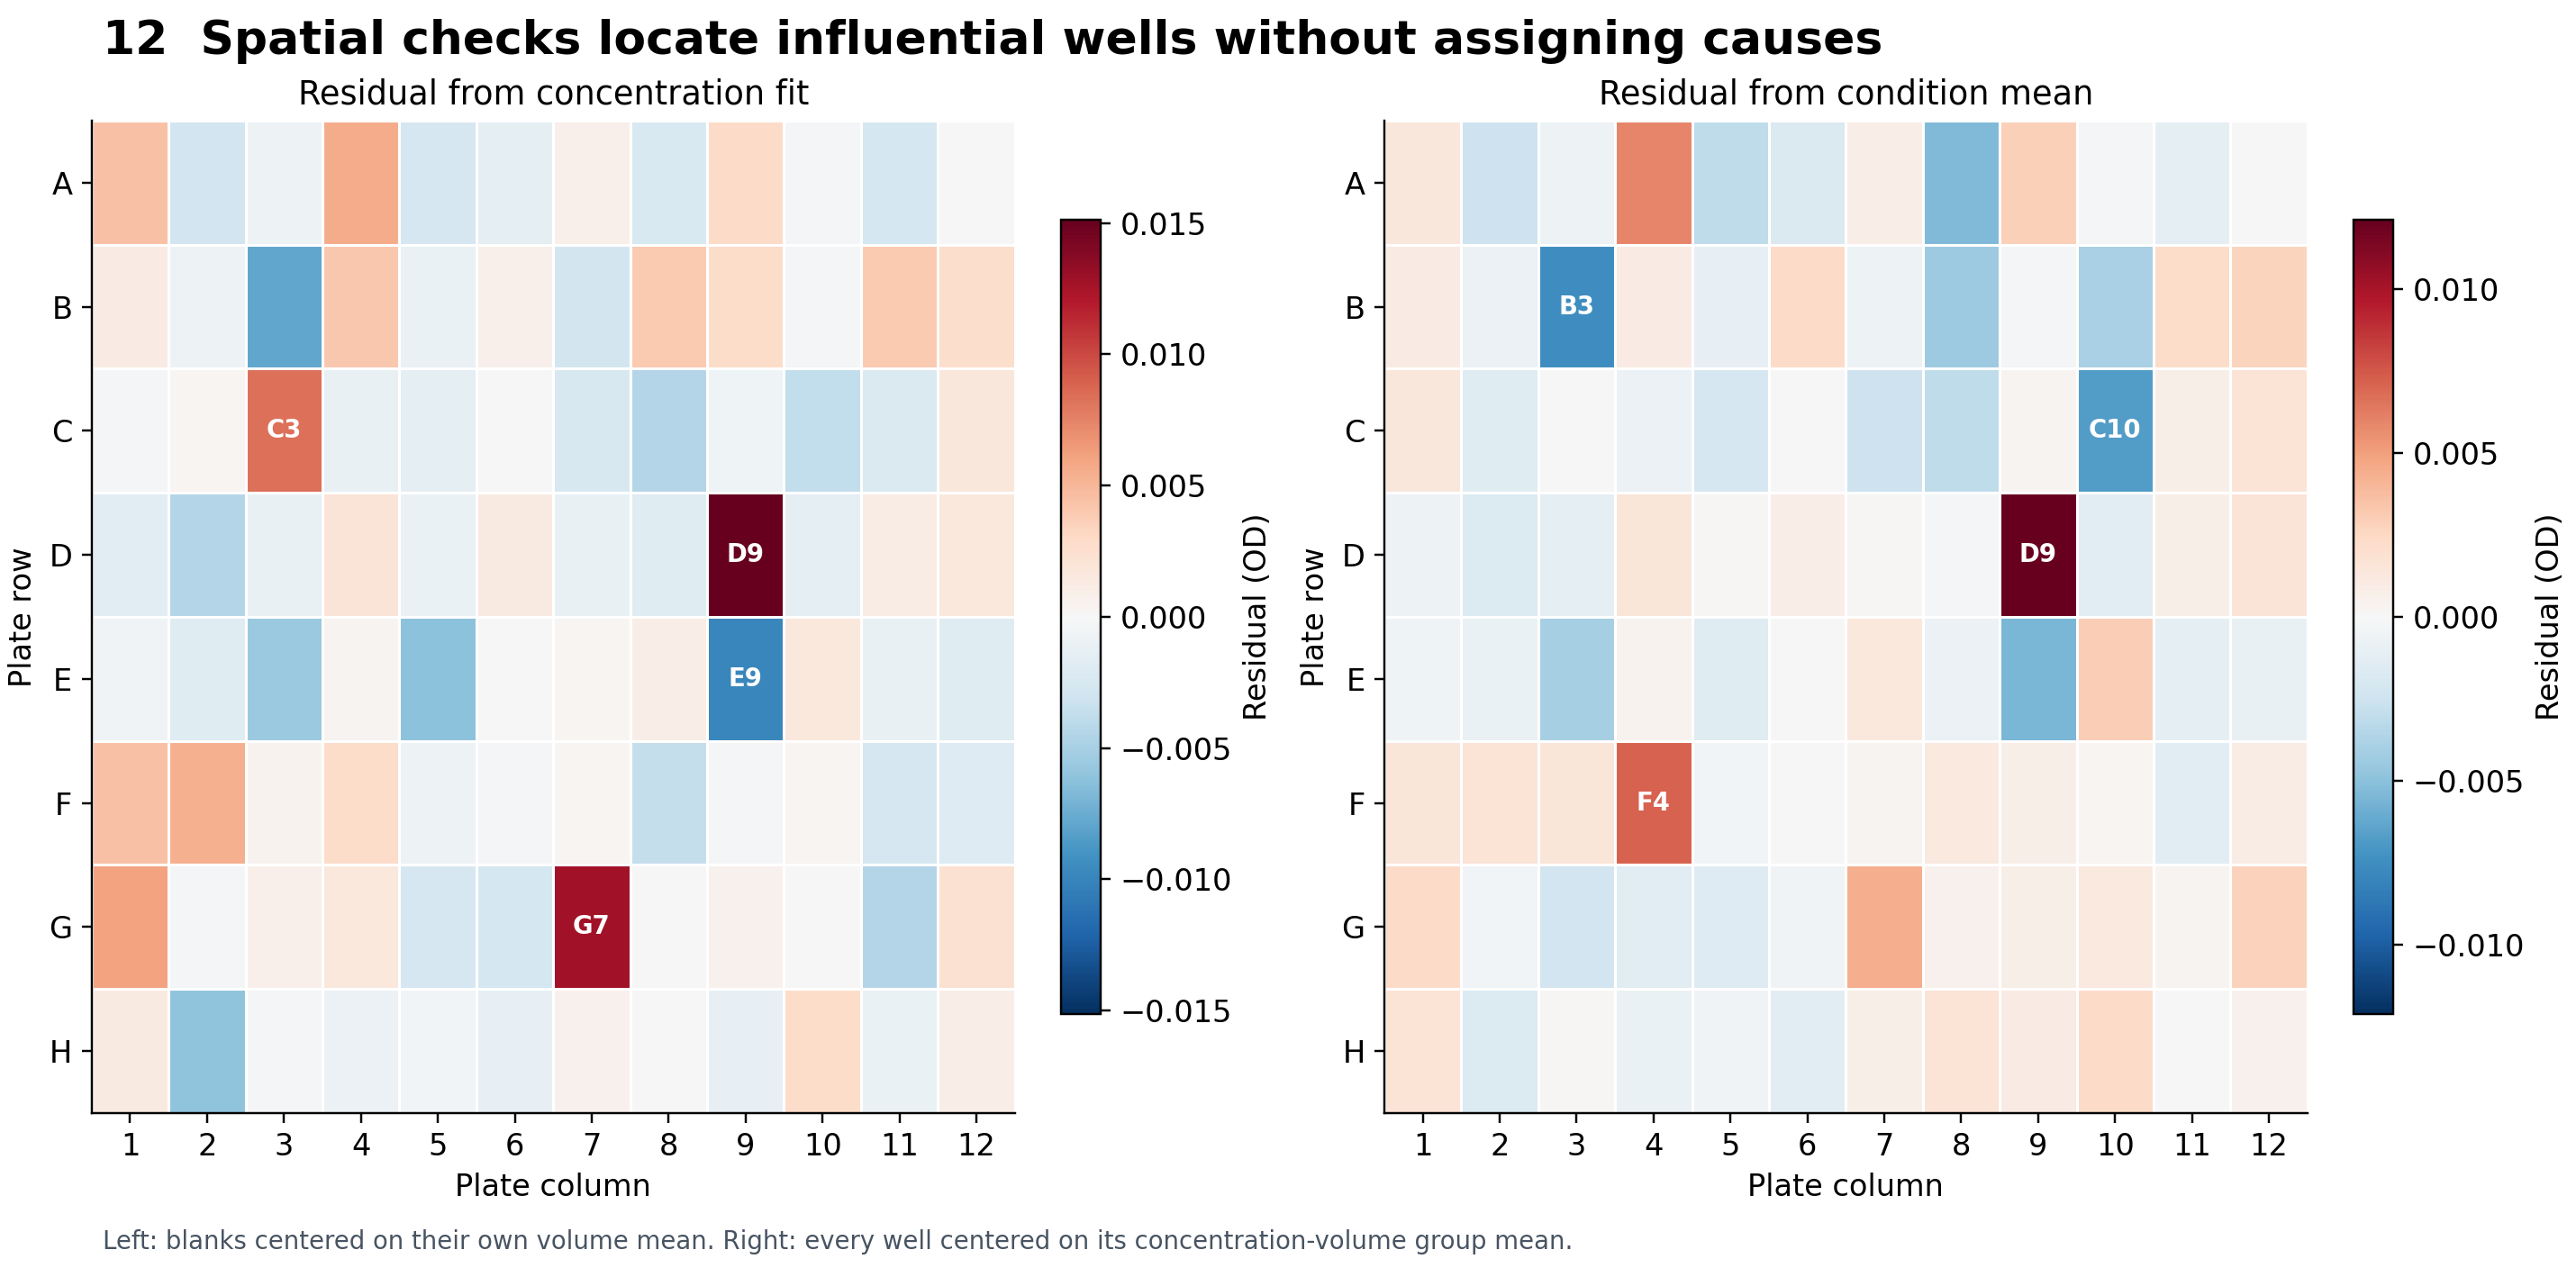

In [17]:
figure = figures[11]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 13  D9 drives the largest low-volume inconsistency

At 50 µL and 2.1875 ng/µL, A8, C10 and D9 read 0.005148, 0.003658 and 0.022558 OD after subtraction. The three-well CV is 100.5%. Omitting D9 only as a sensitivity calculation leaves two wells with CV 23.9%, still uncertain. D9 has no documented physical exclusion reason and is retained in every primary result.

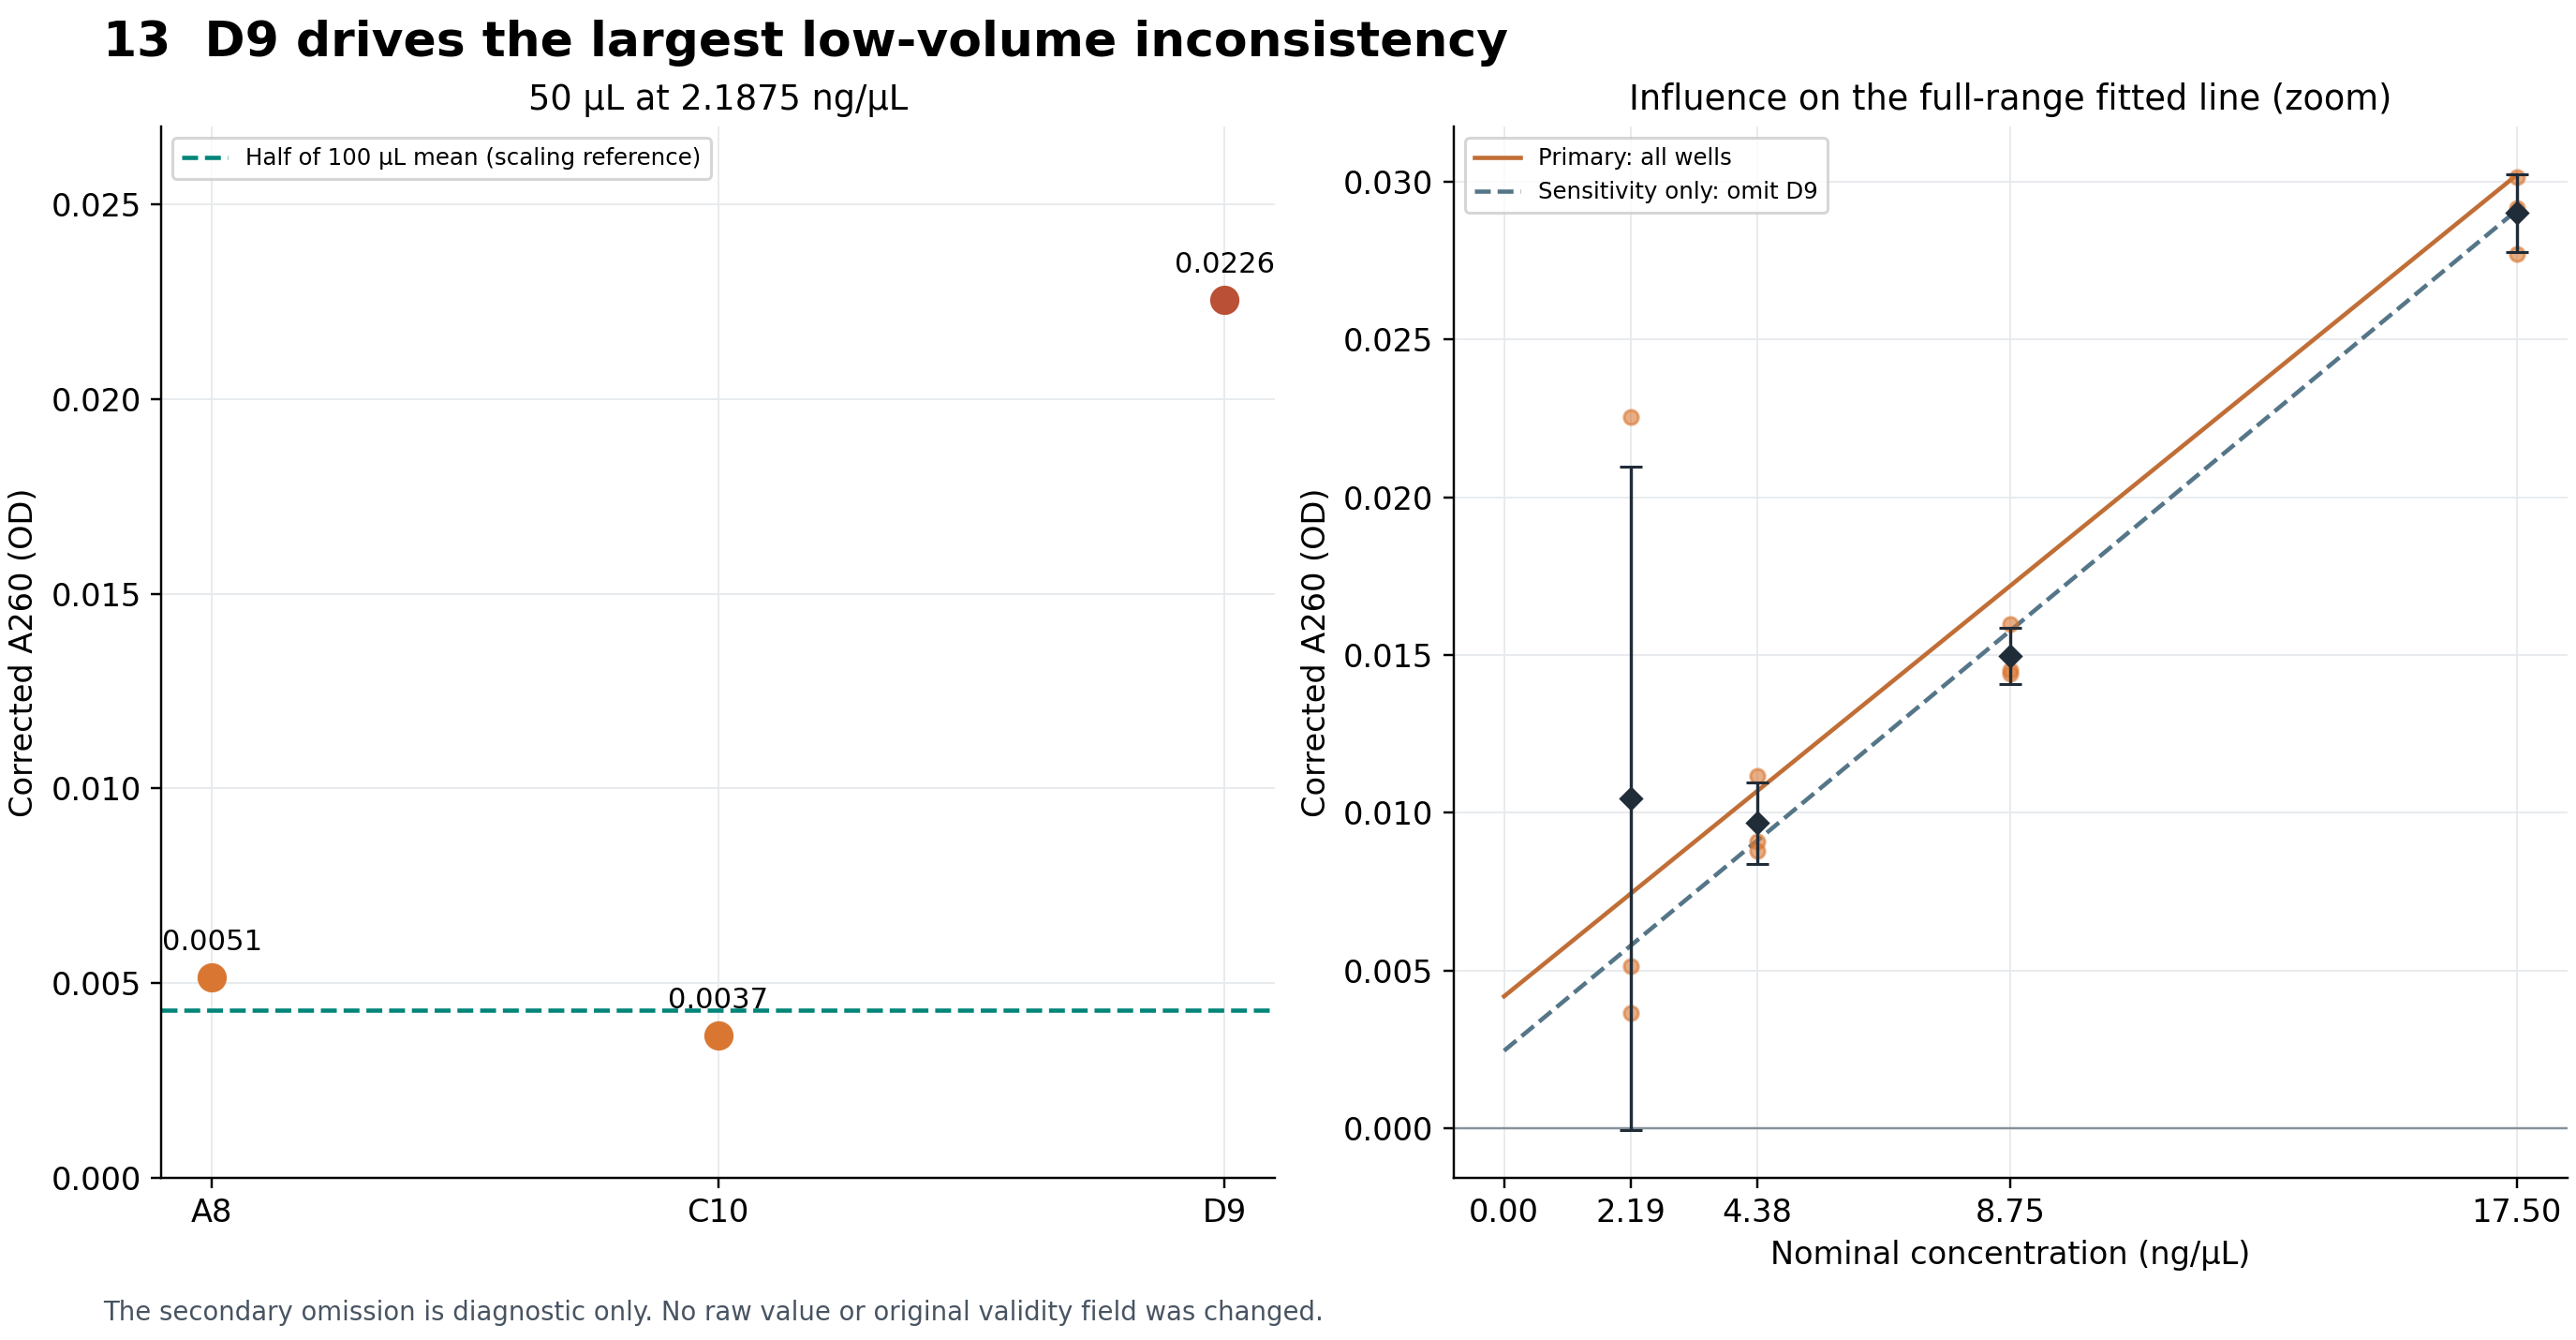

In [18]:
figure = figures[12]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 14  Minimum concentration and minimum sample mass are different goals

At the lowest tested concentration of 2.1875 ng/µL, the wells contain nominally 109.375, 164.063, 218.75 and 437.5 ng at increasing volumes. The 100 µL condition resolves that level with 8.5% within-plate CV using 218.75 ng. Reducing volume saves DNA but reduces optical signal and can expose dispensing or meniscus variability. Actual DNA mass was not independently measured.

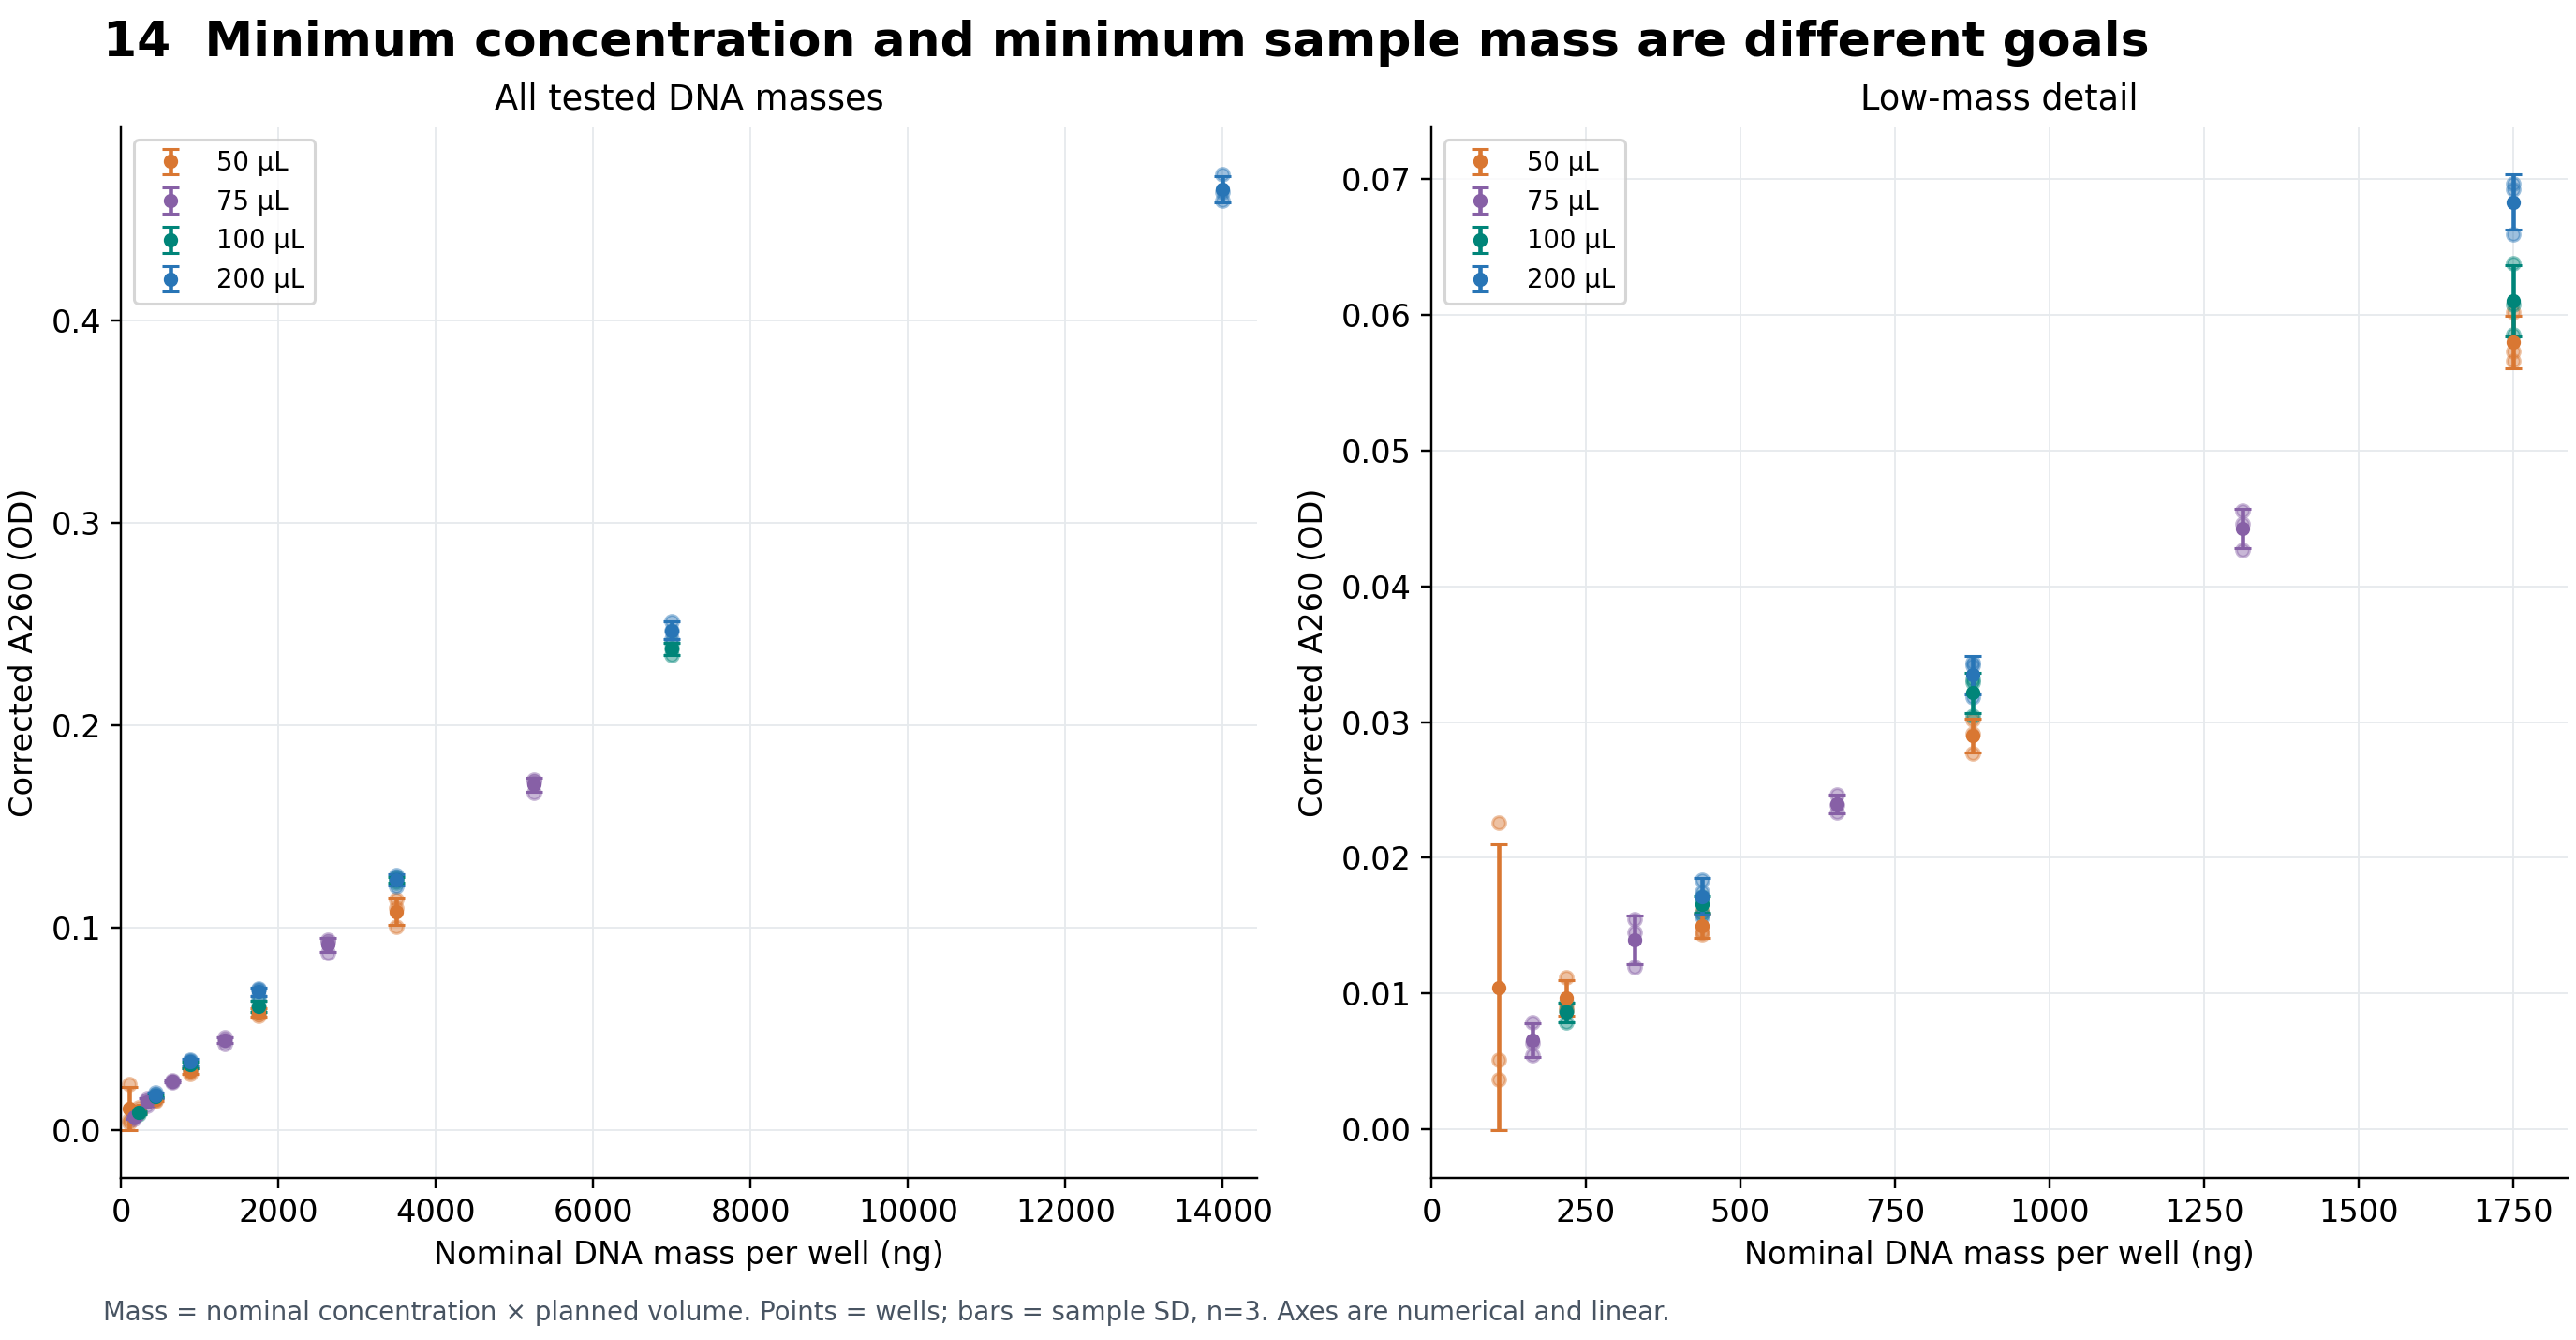

In [19]:
figure = figures[13]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

### 15  Volume-response residuals expose departures from a line

The 35 ng/µL series has an exploratory departure at 200 µL; the 70 ng/µL series has departures at 50, 100 and 200 µL. Lower-concentration series show no clear group departure by this conditional interval rule. The lowest concentration remains imprecise because of D9; absence of a clear departure is not proof of linearity.

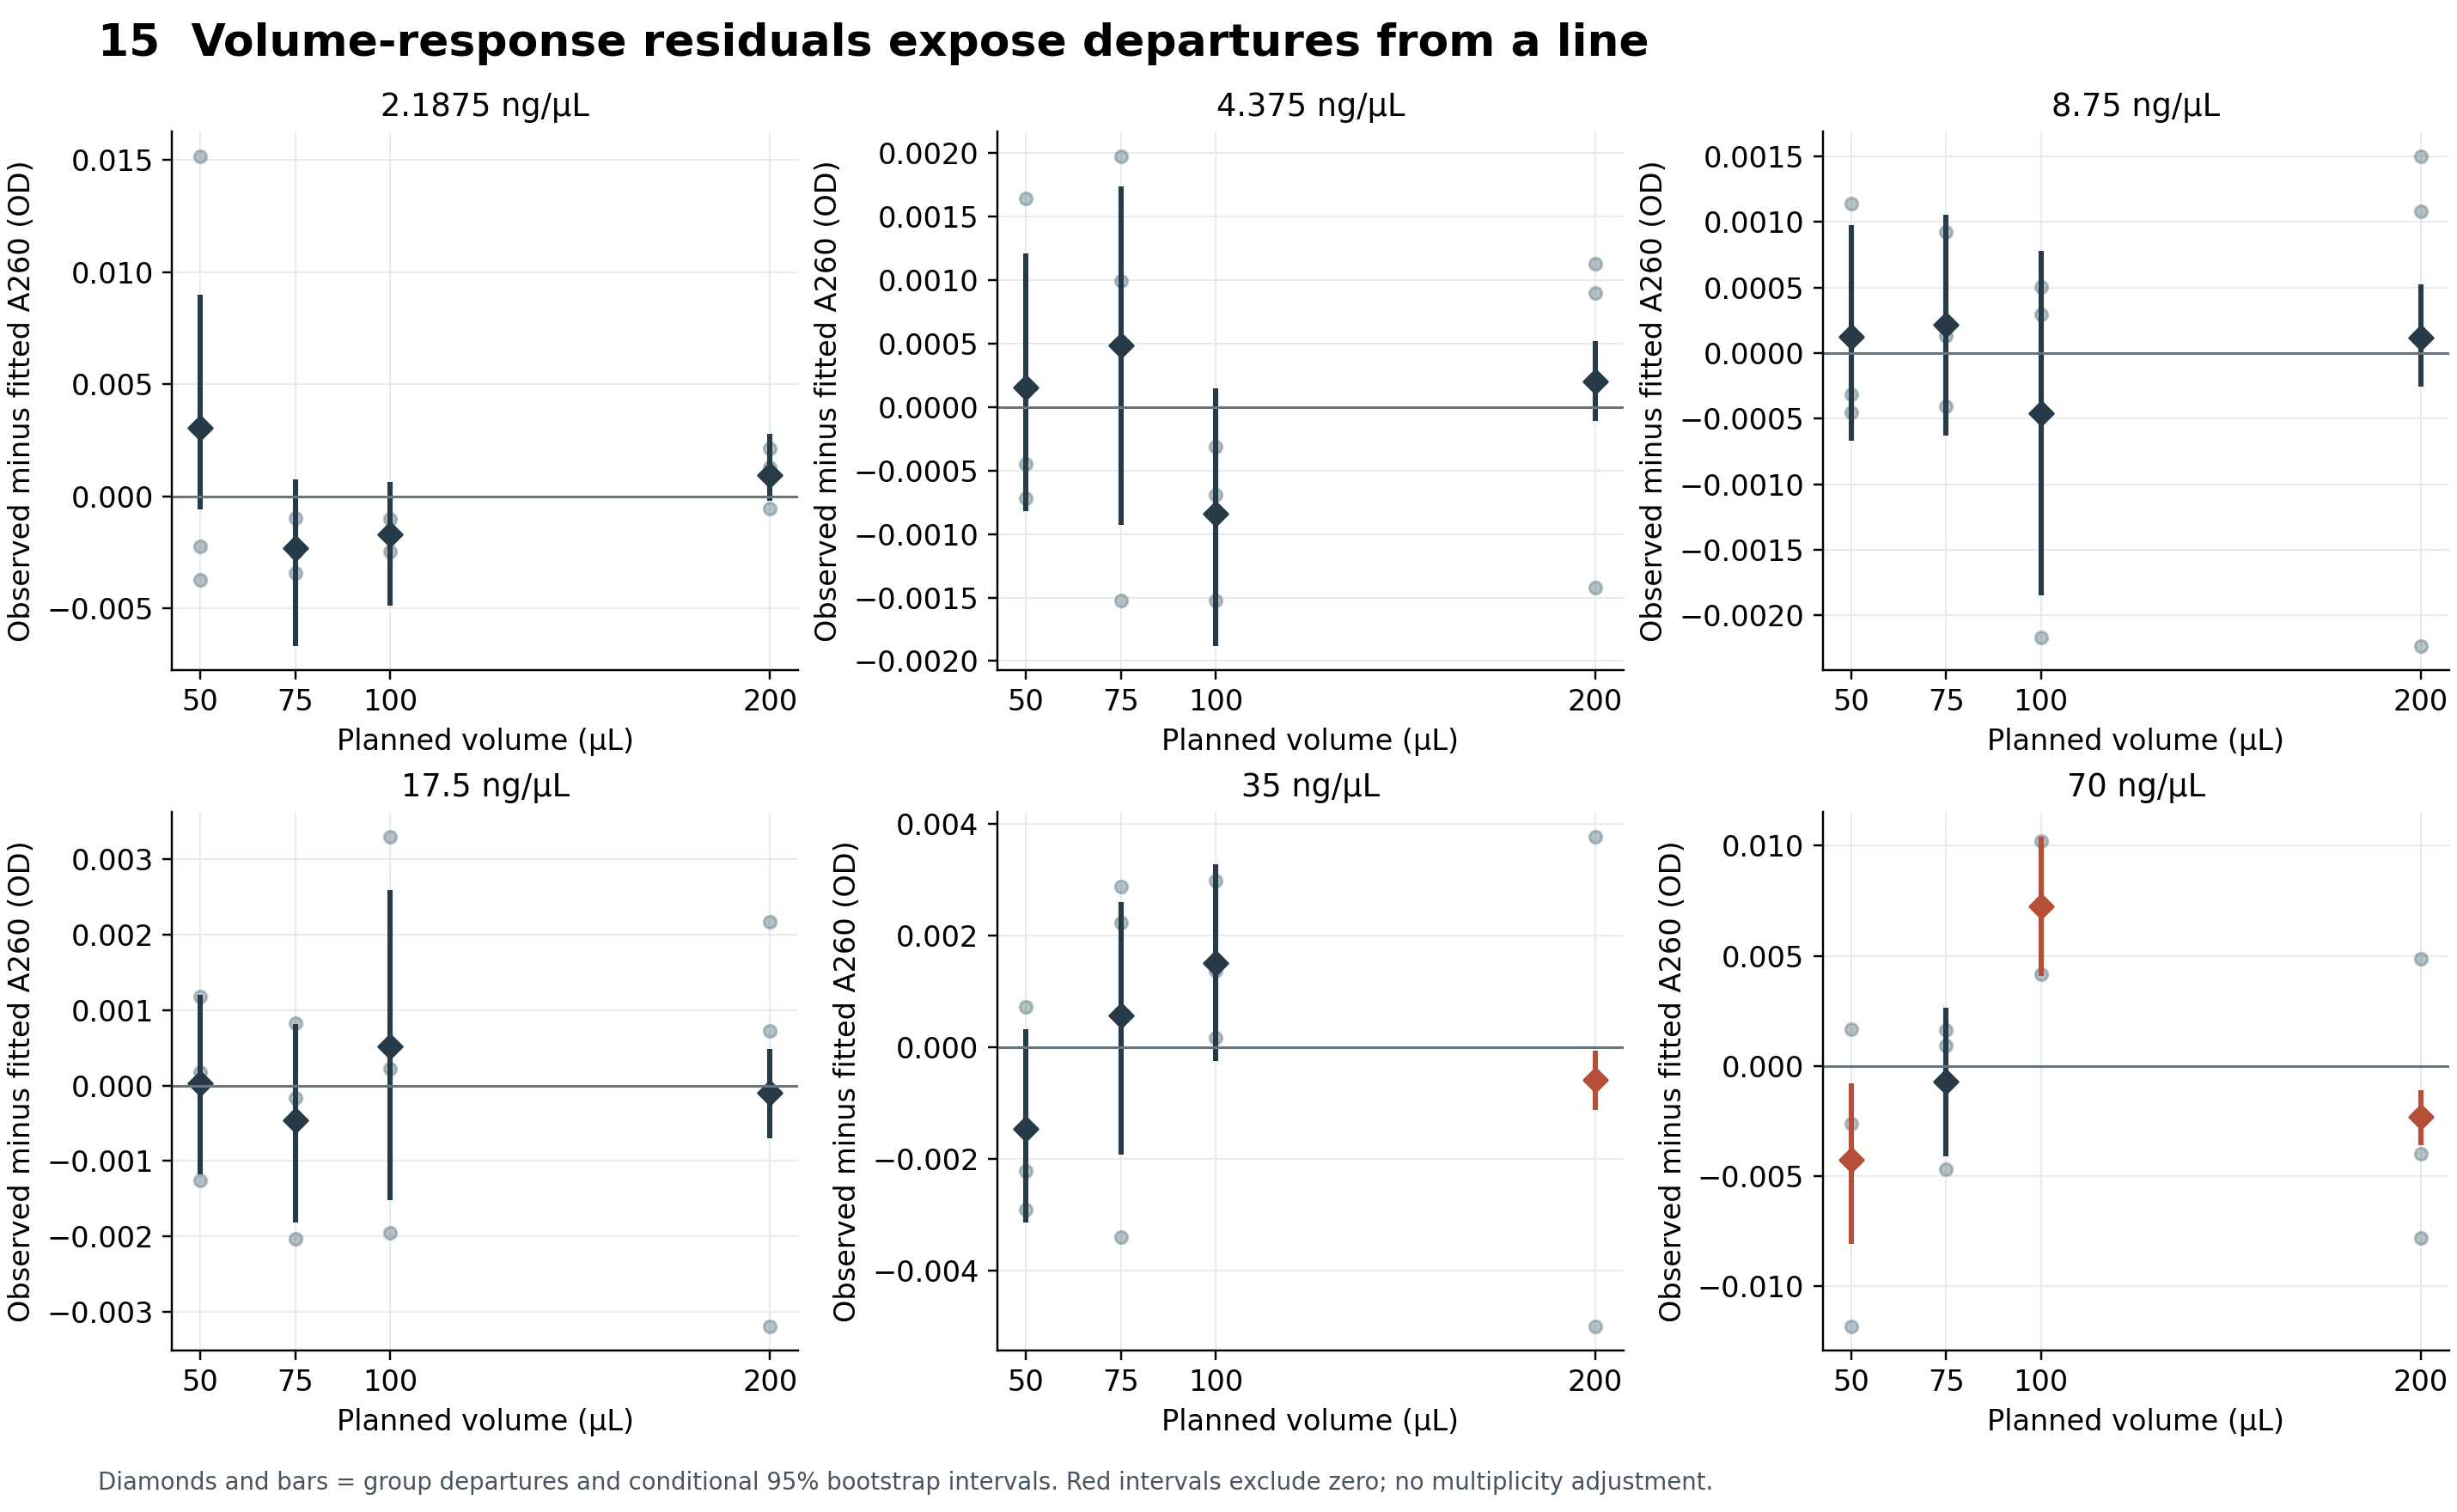

In [20]:
figure = figures[14]
display(Markdown("### " + figure["title"] + "\n\n" + figure["caption"]))
display(Image(filename=str(root / figure["png"]), width=1000))

## Independent verification and next experiment

The verification below checks input hashes, concentration mapping, matched blank arithmetic, all 14 fits against SciPy, and the exploratory-limit arithmetic. If the original files are unavailable after download, the immutable input copies are still hash checked.

A useful follow-up is a new independent dilution series spanning 0.25, 0.5, 1, 2, 4 and 8 ng/µL, with three sample wells and six blanks at each of four volumes (96 wells total). Repeat on separate days and independently check stock and delivered volumes. This would test the proposed ~1 ng/µL noise limit, which the present plate did not reach.

In [21]:
checks = verify(root)
display(checks)
assert checks["independent_scipy_regressions_verified"] == 14
assert checks["preserved_input_hashes_verified"] == 7
print("All file and numerical checks passed; no hardware used.")

{'complete_well_coverage': True,
 'manifest_matches': True,
 'raw_backend_mapping_matches': True,
 'assignment_hash_matches': True,
 'reader_blank_calculations_reproduced': True,
 'reader_corrected_values_reproduced': True,
 'source_files_modified': False,
 'no_wells_excluded': True,
 'independent_scipy_regressions_verified': 14,
 'preserved_input_hashes_verified': 7,
 'original_source_hashes_verified': 7,
 'user_corrected_concentration_mapping_verified': True,
 'negative_blank_corrected_readings_retained': 14,
 'bootstrap_shape_verified': True,
 'exploratory_limit_arithmetic_verified': True}

All file and numerical checks passed; no hardware used.
